# Do sinal ao espectro: um analisador e filtro de sinais de ECG

**Sistematização · Métodos Matemáticos**
Séries de Fourier → Transformada de Fourier → Transformada de Laplace

**Integrantes**

- Enzo Gutiérrez Pereira
- Felipe Abrantes
- Juliano Araújo
- João Lucas Nappo
- Eduardo Regueiro

**Sinal escolhido:** eletrocardiograma (ECG) da base aberta *MIT-BIH Arrhythmia Database* (PhysioNet).
Como o grupo tem cinco integrantes, trabalhamos com **dois sinais** e comparamos **dois tipos de filtro** em cada um:

| | Sinal A | Sinal B |
|---|---|---|
| Registro | 111, de 30 s a 40 s | 203, de 10 s a 20 s |
| Problema | interferência de 60 Hz da rede elétrica | deriva da linha de base (oscilação lenta) |
| Filtro analógico | rejeita-faixa (*notch*) de 2ª ordem | passa-altas RC de 1ª ordem |
| Filtro de comparação | máscara ideal no espectro | máscara ideal no espectro |

**Como executar:** localmente, `uv sync` e depois `uv run jupyter lab`. No Google Colab, basta abrir o notebook e usar *Executar tudo*: se os arquivos de `data/` não estiverem presentes, o notebook baixa os trechos direto do PhysioNet.

## Preparação

In [ ]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from scipy import signal
from scipy.fft import irfft, rfft, rfftfreq

plt.rcParams.update({
    "figure.figsize": (11, 3.6),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})
sp.init_printing()

COR_ORIG, COR_FILT, COR_ALT, COR_DEST = "#8a8a8a", "#1f5fa8", "#d1622b", "#b3261e"

In [ ]:
PASTA_DADOS = Path("data")


def carregar_ecg(registro, inicio_s, duracao_s, fs=360):
    """Devolve (t, x) de um trecho do MIT-BIH, em segundos e mV.

    Usa o .csv de data/ se existir; senão baixa do PhysioNet e salva o .csv.
    """
    arquivo = PASTA_DADOS / f"mitdb_{registro}_{inicio_s}s-{inicio_s + duracao_s}s.csv"
    if not arquivo.exists():
        try:
            import wfdb
        except ImportError:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "wfdb"])
            import wfdb
        reg = wfdb.rdrecord(str(registro), pn_dir="mitdb", channels=[0],
                            sampfrom=inicio_s * fs, sampto=(inicio_s + duracao_s) * fs)
        assert reg.fs == fs and reg.units[0] == "mV"
        x = reg.p_signal[:, 0]
        PASTA_DADOS.mkdir(exist_ok=True)
        np.savetxt(arquivo, np.column_stack([np.arange(len(x)) / fs, x]),
                   delimiter=",", header="t_s,ecg_mV", comments="", fmt="%.6f")
    x = np.loadtxt(arquivo, delimiter=",", skiprows=1, usecols=1)
    return np.arange(len(x)) / fs, x

---
## Etapa 1 · Aproximando funções com ondas (Unidades 1 e 2)

Antes de olhar para o ECG, estudamos o caso clássico. A **onda quadrada** de período $T = 2\pi$ é

$$f(t) = \begin{cases} -1, & -\pi < t < 0 \\ +1, & 0 < t < \pi \end{cases} \qquad f(t + 2\pi) = f(t).$$

A Série de Fourier escreve $f$ como combinação de senos e cossenos de frequências múltiplas da fundamental $\omega_0 = 2\pi/T = 1$:

$$f(t) \sim \frac{a_0}{2} + \sum_{n=1}^{\infty} \big[a_n \cos(n t) + b_n \sin(n t)\big].$$

### 1.1 Por que senos e cossenos servem de base

No intervalo $[-\pi, \pi]$, com o produto interno $\langle g, h\rangle = \int_{-\pi}^{\pi} g(t)\,h(t)\,dt$, as funções $\sin(nt)$ e $\cos(nt)$ são **ortogonais** entre si. A célula abaixo confere isso numericamente para os cinco primeiros senos: a matriz de produtos internos (dividida por $\pi$) é a identidade.

In [ ]:
tg = np.linspace(-np.pi, np.pi, 20001)
gram = np.array([[np.trapezoid(np.sin(m * tg) * np.sin(k * tg), tg) / np.pi
                  for k in range(1, 6)] for m in range(1, 6)])
print("<sen(mt), sen(kt)> / pi  para m, k = 1..5")
print(np.round(gram, 6) + 0.0)

<sen(mt), sen(kt)> / pi  para m, k = 1..5
[[1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 1.]]


Fora da diagonal tudo é zero e, na diagonal, $\langle \sin nt, \sin nt\rangle = \pi$. Por isso cada coeficiente pode ser calculado de forma independente, como a **projeção** de $f$ sobre uma função da base, exatamente como se obtém a componente de um vetor sobre um eixo:

$$b_n = \frac{\langle f, \sin nt\rangle}{\langle \sin nt, \sin nt\rangle} = \frac{1}{\pi}\int_{-\pi}^{\pi} f(t)\sin(nt)\,dt, \qquad a_n = \frac{1}{\pi}\int_{-\pi}^{\pi} f(t)\cos(nt)\,dt.$$

### 1.2 Cálculo dos coeficientes

Calculamos as integrais de forma simbólica com o `sympy`, separando o período nos dois trechos em que $f$ é constante.

In [ ]:
t_ = sp.symbols("t", real=True)
n_ = sp.symbols("n", integer=True, positive=True)


def integral_f_vezes(g):
    """Integral de f(t)*g(t) em um período, com f = -1 em (-pi,0) e +1 em (0,pi)."""
    return sp.integrate(-g, (t_, -sp.pi, 0)) + sp.integrate(g, (t_, 0, sp.pi))


a0 = integral_f_vezes(sp.Integer(1)) / sp.pi
an = sp.simplify(integral_f_vezes(sp.cos(n_ * t_)) / sp.pi)
bn = sp.simplify(integral_f_vezes(sp.sin(n_ * t_)) / sp.pi)

display(sp.Eq(sp.Symbol("a_0"), a0), sp.Eq(sp.Symbol("a_n"), an), sp.Eq(sp.Symbol("b_n"), bn))
print("b_n para n = 1..7:", [bn.subs(n_, k) for k in range(1, 8)])

b_n para n = 1..7: [4/pi, 0, 4/(3*pi), 0, 4/(5*pi), 0, 4/(7*pi)]


**Leitura do resultado.**

- $a_0 = 0$: a onda tem média nula.
- $a_n = 0$ para todo $n$: a onda é uma função **ímpar**, $f(-t) = -f(t)$, e por isso não tem componentes em cosseno (que são pares).
- $b_n = \dfrac{2\,[1-(-1)^n]}{n\pi}$, ou seja, $b_n = \dfrac{4}{n\pi}$ para $n$ ímpar e $b_n = 0$ para $n$ par. Só existem **harmônicos ímpares**, e a amplitude deles cai como $1/n$.

A série fica

$$f(t) \sim \frac{4}{\pi}\left[\sin t + \frac{\sin 3t}{3} + \frac{\sin 5t}{5} + \dots\right].$$

### 1.3 Forma complexa

Usando $e^{i\theta} = \cos\theta + i\sin\theta$, a mesma série pode ser escrita com exponenciais complexas:

$$f(t) \sim \sum_{n=-\infty}^{\infty} c_n\, e^{i n t}, \qquad c_n = \frac{1}{2\pi}\int_{-\pi}^{\pi} f(t)\, e^{-i n t}\,dt.$$

In [ ]:
k_ = sp.symbols("n", integer=True, nonzero=True)
cn = sp.simplify(integral_f_vezes(sp.exp(-sp.I * k_ * t_)) / (2 * sp.pi))
display(sp.Eq(sp.Symbol("c_n"), cn))
print("c_n para n = -3..3 (n != 0):", {k: cn.subs(k_, k) for k in (-3, -2, -1, 1, 2, 3)})
print("c_n == (a_n - i b_n)/2 ?", sp.simplify(cn - (an - sp.I * bn).subs(n_, k_) / 2) == 0)

c_n para n = -3..3 (n != 0): {-3: 2*I/(3*pi), -2: 0, -1: 2*I/pi, 1: -2*I/pi, 2: 0, 3: -2*I/(3*pi)}
c_n == (a_n - i b_n)/2 ? True


Portanto $c_0 = 0$ e, para $n \neq 0$,

$$c_n = \frac{i\,[(-1)^n - 1]}{n\pi} = \begin{cases} -\dfrac{2i}{n\pi}, & n \text{ ímpar} \\[2mm] 0, & n \text{ par.} \end{cases}$$

Três observações ligam a forma complexa à forma real:

- $c_n = \tfrac{1}{2}(a_n - i\,b_n)$, conferido acima. Como $a_n = 0$, os $c_n$ são **imaginários puros**.
- $c_{-n} = \overline{c_n}$, o que garante que a soma das exponenciais seja real.
- $|c_n| = \dfrac{2}{|n|\pi}$ é o **espectro de amplitudes** da onda quadrada: uma sequência de raias nas frequências ímpares. É essa ideia de "amplitude por frequência" que a Transformada de Fourier da Etapa 2 estende a sinais não periódicos.

### 1.4 Somas parciais: a aproximação melhorando

A soma parcial $S_N(t)$ usa os harmônicos até a ordem $N$. Implementamos as duas formas (real e complexa) e conferimos que dão o mesmo resultado.

In [ ]:
def onda_quadrada(t):
    return np.sign(np.sin(t))


def soma_parcial(t, N):
    """Forma real: soma de (4/(n pi)) sen(n t) para n ímpar <= N."""
    S = np.zeros_like(t, dtype=float)
    for n in range(1, N + 1, 2):
        S += 4 / (n * np.pi) * np.sin(n * t)
    return S


def soma_parcial_complexa(t, N):
    """Forma complexa: soma de c_n e^{int} para |n| <= N, com c_n = -2i/(n pi), n ímpar."""
    S = np.zeros_like(t, dtype=complex)
    for n in range(-N, N + 1):
        if n % 2:
            S += (-2j / (n * np.pi)) * np.exp(1j * n * t)
    return S


tt = np.linspace(-np.pi, np.pi, 4001)
dif = np.max(np.abs(soma_parcial(tt, 49) - soma_parcial_complexa(tt, 49)))
print(f"Maior diferença entre forma real e complexa (N=49): {dif:.1e}")
print(f"Maior parte imaginária da soma complexa: {np.max(np.abs(soma_parcial_complexa(tt, 49).imag)):.1e}")

Maior diferença entre forma real e complexa (N=49): 1.8e-15
Maior parte imaginária da soma complexa: 2.8e-16


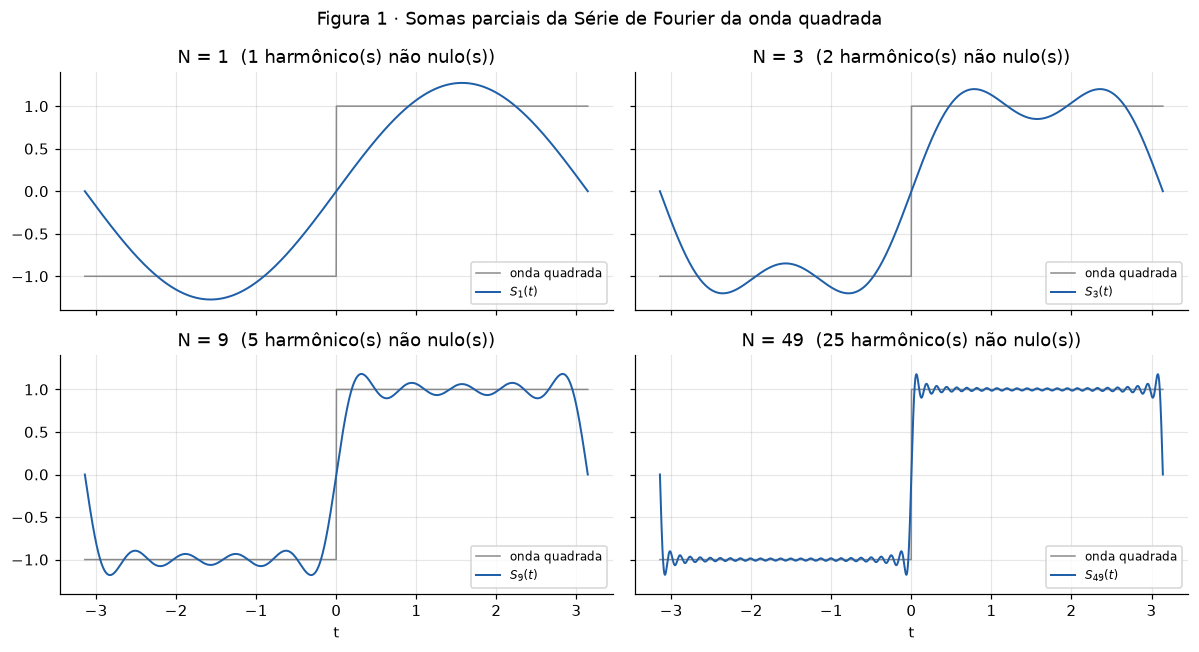

In [ ]:
fig, eixos = plt.subplots(2, 2, figsize=(11, 6), sharex=True, sharey=True)
for ax, N in zip(eixos.ravel(), [1, 3, 9, 49]):
    ax.plot(tt, onda_quadrada(tt), color=COR_ORIG, lw=1, label="onda quadrada")
    ax.plot(tt, soma_parcial(tt, N), color=COR_FILT, lw=1.3, label=f"$S_{{{N}}}(t)$")
    ax.set_title(f"N = {N}  ({(N + 1) // 2} harmônico(s) não nulo(s))")
    ax.legend(loc="lower right", fontsize=8)
for ax in eixos[1]:
    ax.set_xlabel("t")
fig.suptitle("Figura 1 · Somas parciais da Série de Fourier da onda quadrada")
fig.tight_layout()
plt.show()

**Figura 1.** Com $N = 1$ temos apenas um seno, que acerta o período e o sinal da onda, mas não a forma. Cada harmônico ímpar acrescentado "achata" os patamares e deixa as subidas mais íngremes. Com $N = 49$ a aproximação é muito boa em quase todos os pontos. Sobram, porém, dois detalhes que não desaparecem: no salto, a soma passa exatamente por $0$ (a média entre $-1$ e $+1$), e logo ao lado dele aparece um pico que ultrapassa o valor da onda.

### 1.5 Convergência: o erro quadrático médio

Para medir a qualidade da aproximação usamos o erro quadrático médio em um período, $E_N = \frac{1}{2\pi}\int_{-\pi}^{\pi} [f(t) - S_N(t)]^2\,dt$. Pela identidade de Parseval, a potência média de $f$ (que vale 1) é a soma das potências dos harmônicos, então o erro é o que ainda falta somar:

$$E_N = 1 - \sum_{\substack{n \le N \\ n \text{ ímpar}}} \frac{b_n^2}{2} = 1 - \frac{8}{\pi^2}\sum_{\substack{n \le N \\ n \text{ ímpar}}} \frac{1}{n^2}.$$

N =    1   erro numérico = 0.18943   Parseval = 0.18943   E_N * N = 0.189
N =    3   erro numérico = 0.09937   Parseval = 0.09937   E_N * N = 0.298
N =    5   erro numérico = 0.06694   Parseval = 0.06694   E_N * N = 0.335
N =    9   erro numérico = 0.04040   Parseval = 0.04040   E_N * N = 0.364
N =   19   erro numérico = 0.02025   Parseval = 0.02025   E_N * N = 0.385
N =   49   erro numérico = 0.00810   Parseval = 0.00810   E_N * N = 0.397
N =   99   erro numérico = 0.00405   Parseval = 0.00405   E_N * N = 0.401
N =  199   erro numérico = 0.00203   Parseval = 0.00203   E_N * N = 0.403
N =  499   erro numérico = 0.00081   Parseval = 0.00081   E_N * N = 0.404


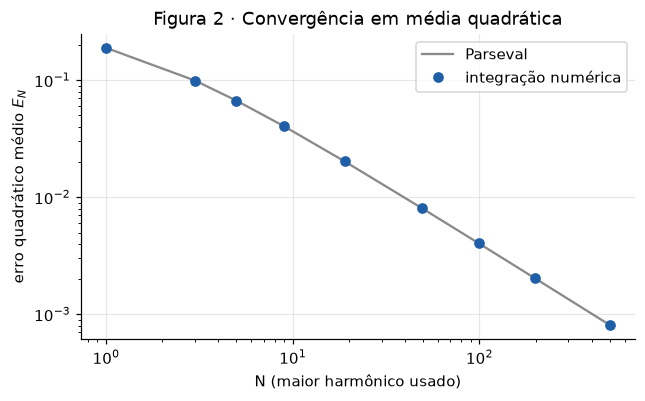

In [ ]:
Ns = np.array([1, 3, 5, 9, 19, 49, 99, 199, 499])
tf = np.linspace(-np.pi, np.pi, 200001)
erro_num = [np.trapezoid((onda_quadrada(tf) - soma_parcial(tf, N)) ** 2, tf) / (2 * np.pi) for N in Ns]
erro_parseval = [1 - 8 / np.pi**2 * sum(1 / n**2 for n in range(1, N + 1, 2)) for N in Ns]

for N, e1, e2 in zip(Ns, erro_num, erro_parseval):
    print(f"N = {N:4d}   erro numérico = {e1:.5f}   Parseval = {e2:.5f}   E_N * N = {e2 * N:.3f}")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.loglog(Ns, erro_parseval, "-", color=COR_ORIG, label="Parseval")
ax.loglog(Ns, erro_num, "o", color=COR_FILT, label="integração numérica")
ax.set_xlabel("N (maior harmônico usado)")
ax.set_ylabel("erro quadrático médio $E_N$")
ax.set_title("Figura 2 · Convergência em média quadrática")
ax.legend()
plt.show()

**Figura 2.** O erro quadrático médio cai continuamente e tende a zero. No gráfico log-log ele aparece como uma reta de inclinação $-1$, isto é, $E_N \propto 1/N$ (a coluna $E_N \cdot N$ da tabela se estabiliza perto de $0{,}4$). É uma convergência **lenta**, consequência direta de os coeficientes caírem apenas como $1/n$, o que por sua vez é a marca de uma função com descontinuidade. Funções contínuas têm coeficientes que caem mais rápido e precisam de menos termos.

### 1.6 O fenômeno de Gibbs

Convergir em média não significa convergir bem em todos os pontos. Vamos olhar de perto a vizinhança do salto em $t = 0$ e medir o valor máximo de $S_N$.

   N    máximo de S_N   posição do pico   pi/(N+1)   overshoot (% do salto)
    9    1.18233         0.31416          0.31416    9.12 %
   49    1.17911         0.06283          0.06283    8.96 %
  199    1.17899         0.01571          0.01571    8.95 %
  999    1.17898         0.00314          0.00314    8.95 %
 4999    1.17898         0.00063          0.00063    8.95 %


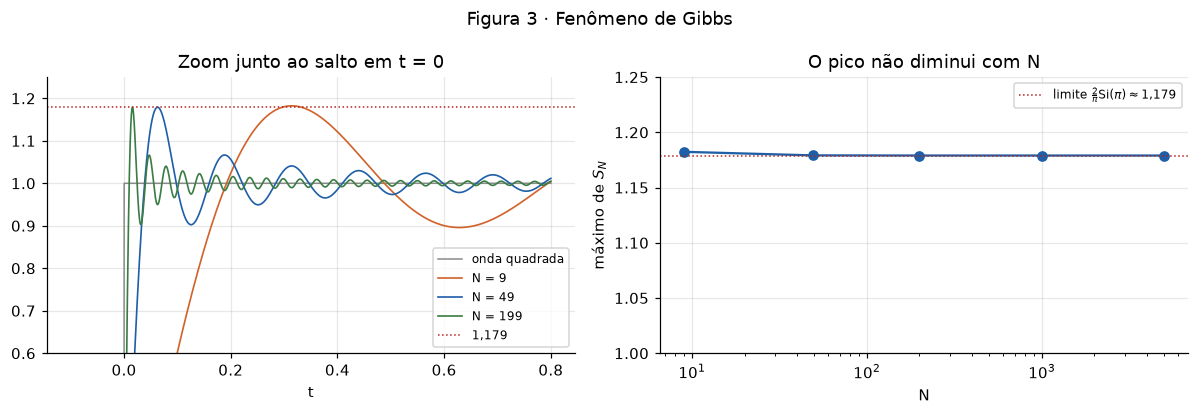

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
tz = np.linspace(-0.1, 0.8, 6001)
ax1.plot(tz, onda_quadrada(tz), color=COR_ORIG, lw=1, label="onda quadrada")
for N, cor in zip([9, 49, 199], [COR_ALT, COR_FILT, "#3a7d44"]):
    ax1.plot(tz, soma_parcial(tz, N), color=cor, lw=1.1, label=f"N = {N}")
ax1.axhline(1.17898, color=COR_DEST, ls=":", lw=1, label="1,179")
ax1.set_ylim(0.6, 1.25)
ax1.set_xlabel("t")
ax1.set_title("Zoom junto ao salto em t = 0")
ax1.legend(fontsize=8)

print("   N    máximo de S_N   posição do pico   pi/(N+1)   overshoot (% do salto)")
Ns_g = [9, 49, 199, 999, 4999]
picos = []
for N in Ns_g:
    tp = np.linspace(1e-9, 4 * np.pi / (N + 1), 4001)
    S = soma_parcial(tp, N)
    i = np.argmax(S)
    picos.append(S[i])
    print(f"{N:5d}    {S[i]:.5f}         {tp[i]:.5f}          {np.pi / (N + 1):.5f}    {(S[i] - 1) / 2 * 100:.2f} %")

ax2.semilogx(Ns_g, picos, "o-", color=COR_FILT)
ax2.axhline(1.17898, color=COR_DEST, ls=":", lw=1, label=r"limite $\frac{2}{\pi}\mathrm{Si}(\pi) \approx 1{,}179$")
ax2.set_ylim(1.0, 1.25)
ax2.set_xlabel("N")
ax2.set_ylabel("máximo de $S_N$")
ax2.set_title("O pico não diminui com N")
ax2.legend(fontsize=8)
fig.suptitle("Figura 3 · Fenômeno de Gibbs")
fig.tight_layout()
plt.show()

**Figura 3.** O pico ao lado da descontinuidade **não diminui** quando somamos mais termos: ele se estabiliza em cerca de $1{,}179$, um excesso de $0{,}179$, que corresponde a aproximadamente **9% da altura do salto** (o salto vale 2). O valor limite é $\frac{2}{\pi}\,\mathrm{Si}(\pi)$, onde $\mathrm{Si}$ é a integral seno.

O que muda com $N$ é a **largura** do pico: ele ocorre em $t = \pi/(N+1)$ e vai sendo espremido contra o salto. Assim:

- em qualquer ponto fixo $t \neq 0$, a série converge para $f(t)$ (convergência pontual);
- no ponto do salto, converge para a média dos limites laterais, $0$;
- a área sob o pico vai a zero, por isso o erro quadrático médio vai a zero mesmo com o pico presente;
- mas o erro máximo não vai a zero: a convergência **não é uniforme**.

A explicação é que estamos tentando construir um salto, que exigiria frequências arbitrariamente altas, com um número finito de ondas suaves. **Truncar o espectro de forma abrupta gera oscilações no tempo.** Esse resultado volta a aparecer na Etapa 3, quando zeramos faixas do espectro do ECG com um filtro ideal.

---
## Etapa 2 · Do tempo para a frequência (Unidade 3)

### 2.1 Os sinais

Os dois trechos vêm do *MIT-BIH Arrhythmia Database*: gravações de ECG ambulatorial digitalizadas a **360 amostras por segundo**, com amplitude em milivolts. Usamos o primeiro canal de cada registro.

In [ ]:
fs = 360                      # taxa de amostragem (Hz), informada no cabeçalho dos registros
tA, xA = carregar_ecg(111, 30, 10, fs)
tB, xB = carregar_ecg(203, 10, 10, fs)

N = len(xA)
print(f"Amostras por sinal: N = {N}")
print(f"Taxa de amostragem: fs = {fs} Hz  ->  intervalo entre amostras = {1000 / fs:.2f} ms")
print(f"Duração: {N / fs:.1f} s")
print(f"Frequência de Nyquist: fs/2 = {fs / 2:.0f} Hz")
print(f"Resolução em frequência: fs/N = {fs / N:.2f} Hz")

Amostras por sinal: N = 3600
Taxa de amostragem: fs = 360 Hz  ->  intervalo entre amostras = 2.78 ms
Duração: 10.0 s
Frequência de Nyquist: fs/2 = 180 Hz
Resolução em frequência: fs/N = 0.10 Hz


**Amostragem e Nyquist.** Um sinal amostrado a $f_s$ só representa sem ambiguidade frequências até $f_s/2$ (teorema da amostragem). Aqui $f_s/2 = 180$ Hz, com folga em relação ao conteúdo útil do ECG (até uns 40 Hz, chegando a 100 Hz nos detalhes do complexo QRS) e também em relação aos 60 Hz da rede elétrica, que portanto aparecem na posição correta do espectro, sem *aliasing*. A outra grandeza importante é a **resolução**: com $N = 3600$ amostras, cada ponto da FFT está separado de $f_s/N = 0{,}1$ Hz do vizinho. É a duração de 10 s que define essa resolução ($1/10\,\text{s} = 0{,}1$ Hz).

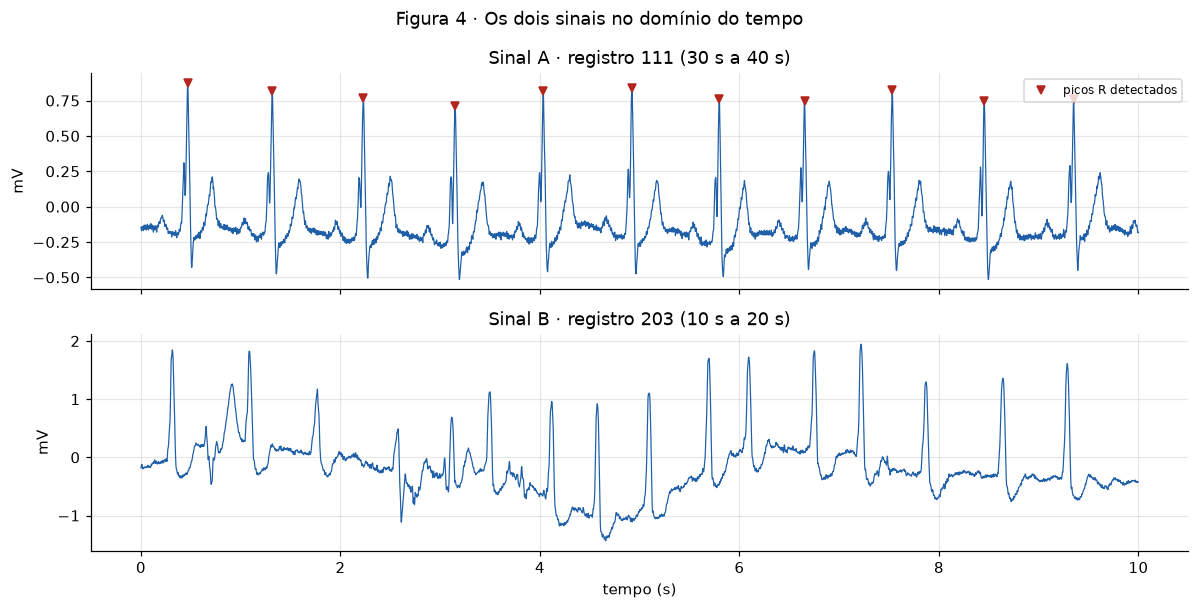

Sinal A: 11 batimentos em 10 s; intervalo RR médio = 0.888 s -> 67.6 bpm = 1.13 Hz
Sinal B: excursão total = 3.38 mV


In [ ]:
def detectar_picos_R(x, fs):
    """Índices dos picos R: máximos acima de 60% do maior, separados por >= 0,3 s."""
    xc = x - np.median(x)
    picos, _ = signal.find_peaks(xc, height=0.6 * xc.max(), distance=int(0.3 * fs))
    return picos


rA = detectar_picos_R(xA, fs)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 5.6), sharex=True)
ax1.plot(tA, xA, color=COR_FILT, lw=0.8)
ax1.plot(tA[rA], xA[rA], "v", color=COR_DEST, ms=5, label="picos R detectados")
ax1.set_title("Sinal A · registro 111 (30 s a 40 s)")
ax1.set_ylabel("mV")
ax1.legend(loc="upper right", fontsize=8)
ax2.plot(tB, xB, color=COR_FILT, lw=0.8)
ax2.set_title("Sinal B · registro 203 (10 s a 20 s)")
ax2.set_ylabel("mV")
ax2.set_xlabel("tempo (s)")
fig.suptitle("Figura 4 · Os dois sinais no domínio do tempo")
fig.tight_layout()
plt.show()

rr = np.diff(tA[rA])
print(f"Sinal A: {len(rA)} batimentos em {N / fs:.0f} s; intervalo RR médio = {rr.mean():.3f} s "
      f"-> {60 / rr.mean():.1f} bpm = {1 / rr.mean():.2f} Hz")
print(f"Sinal B: excursão total = {np.ptp(xB):.2f} mV")

**Figura 4.**

- **Sinal A.** Um ECG de ritmo regular: 11 batimentos em 10 s, intervalo médio entre picos R de 0,888 s, ou seja, **67,6 bpm (1,13 Hz)**. Cada batimento tem a forma esperada: uma onda P pequena, o complexo QRS estreito e alto (cerca de 1 mV) e a onda T mais larga. A olho nu o traçado parece limpo, apenas com uma leve "aspereza". Nada no gráfico sugere uma interferência de 60 Hz.
- **Sinal B.** Um ECG de ritmo irregular, com batimentos de formas diferentes entre si. O que chama a atenção é que a **linha de base sobe e desce lentamente**: começa perto de 0 mV, desce até cerca de −1 mV por volta de 4,5 s e volta a subir. Essa oscilação, que leva vários segundos, não vem do coração: é a deriva da linha de base, causada tipicamente pela respiração e pelo movimento dos eletrodos. Ela é da mesma ordem de grandeza dos próprios batimentos e atrapalha a leitura das amplitudes.

No tempo, portanto, o problema do sinal B é evidente e o do sinal A é invisível. Vamos ver o que o domínio da frequência mostra.

In [ ]:
def espectro(x, fs):
    """Espectro de amplitude unilateral: frequências (Hz) e amplitudes (mesma unidade de x)."""
    X = rfft(x - np.mean(x))
    f = rfftfreq(len(x), d=1 / fs)
    return f, 2 * np.abs(X) / len(x)


fA, AA = espectro(xA, fs)
fB, AB = espectro(xB, fs)

### 2.2 Como o espectro é calculado

A Transformada de Fourier $X(f) = \int x(t)\,e^{-i2\pi f t}\,dt$ faz com um sinal qualquer o que os coeficientes $c_n$ da Etapa 1 fazem com um sinal periódico: mede "quanto" de cada frequência existe nele. Para um sinal amostrado, o computador calcula a **Transformada Discreta de Fourier** pelo algoritmo FFT:

$$X[k] = \sum_{m=0}^{N-1} x[m]\, e^{-i 2\pi k m / N}, \qquad f_k = k\,\frac{f_s}{N}.$$

Três cuidados na função `espectro`:

- usamos `rfft`, que devolve só as frequências de $0$ a $f_s/2$. Como o sinal é real, a metade negativa é o conjugado da positiva (o mesmo $c_{-n} = \overline{c_n}$ da Etapa 1) e não traz informação nova;
- multiplicamos por $2/N$ para que uma senoide de amplitude $A$ apareça como um pico de altura $A$, na mesma unidade do sinal (mV);
- subtraímos a média antes, porque o nível constante do registro (componente em $f = 0$) é muito maior que o resto e esconderia o gráfico.

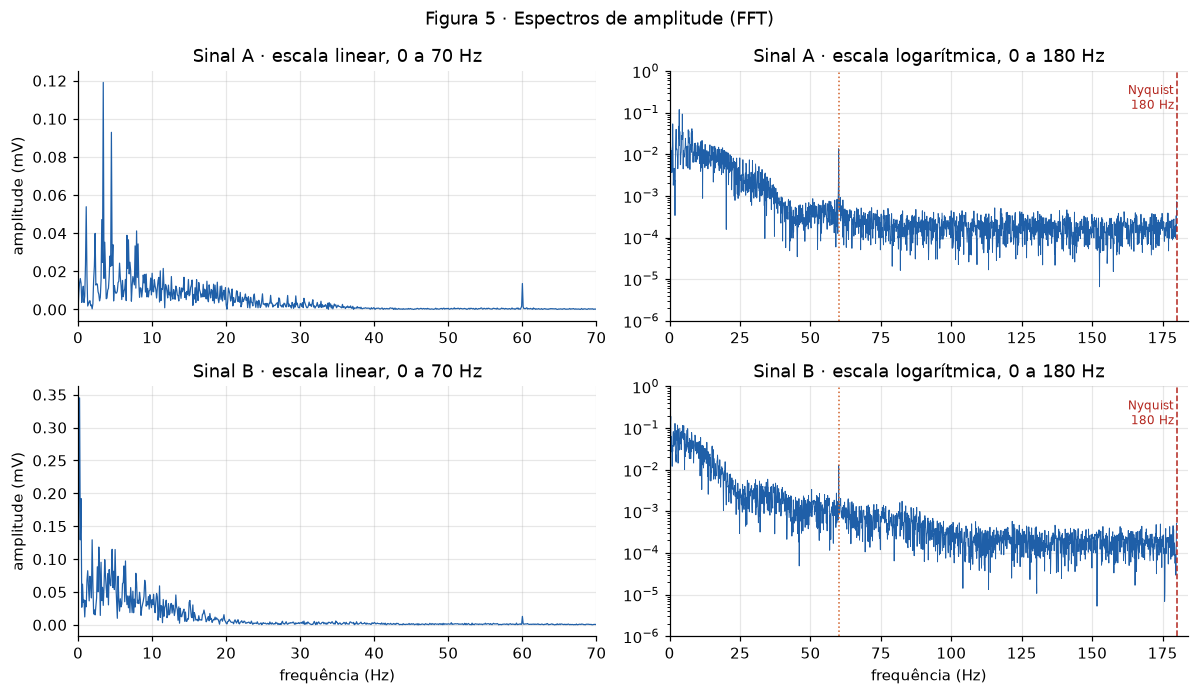

In [ ]:
def marcar_nyquist(ax):
    ax.axvline(fs / 2, color=COR_DEST, ls="--", lw=1)
    ax.text(fs / 2 - 1, 0.95, "Nyquist\n180 Hz", color=COR_DEST, ha="right", va="top",
            fontsize=8, transform=ax.get_xaxis_transform())


fig, eixos = plt.subplots(2, 2, figsize=(11, 6.4))
for linha, (f, A, nome) in enumerate([(fA, AA, "Sinal A"), (fB, AB, "Sinal B")]):
    ax = eixos[linha, 0]
    ax.plot(f, A, color=COR_FILT, lw=0.8)
    ax.set_xlim(0, 70)
    ax.set_ylabel("amplitude (mV)")
    ax.set_title(f"{nome} · escala linear, 0 a 70 Hz")
    ax = eixos[linha, 1]
    ax.semilogy(f[1:], A[1:], color=COR_FILT, lw=0.6)
    ax.set_xlim(0, fs / 2 + 4)
    ax.set_ylim(1e-6, 1)
    ax.axvline(60, color=COR_ALT, ls=":", lw=1)
    marcar_nyquist(ax)
    ax.set_title(f"{nome} · escala logarítmica, 0 a 180 Hz")
for ax in eixos[1]:
    ax.set_xlabel("frequência (Hz)")
fig.suptitle("Figura 5 · Espectros de amplitude (FFT)")
fig.tight_layout()
plt.show()

In [ ]:
def pico_na_faixa(f, A, f1, f2):
    m = (f >= f1) & (f <= f2)
    i = np.argmax(A[m])
    return f[m][i], A[m][i]


def fracao_energia(f, A, f1, f2):
    m = (f >= f1) & (f < f2)
    return np.sum(A[m] ** 2) / np.sum(A[1:] ** 2)


for nome, f, A in [("A", fA, AA), ("B", fB, AB)]:
    print(f"--- Sinal {nome} ---")
    fp, Ap = pico_na_faixa(f, A, 0.1, 180)
    print(f"Maior componente: {fp:.1f} Hz, amplitude {Ap:.3f} mV")
    f60, A60 = pico_na_faixa(f, A, 55, 65)
    viz = np.median(A[((f > 50) & (f < 58)) | ((f > 62) & (f < 70))])
    print(f"Pico perto de 60 Hz: {f60:.1f} Hz, amplitude {A60 * 1000:.1f} uV "
          f"({A60 / viz:.0f} vezes o nível vizinho)")
    for f1, f2 in [(0, 0.5), (0.5, 40), (40, 58), (58, 62), (62, 180)]:
        print(f"  energia em [{f1:5.1f}, {f2:5.1f}) Hz: {100 * fracao_energia(f, A, f1, f2):6.2f} %")

fbat, _ = pico_na_faixa(fA, AA, 0.8, 2.0)
print(f"\nSinal A: pico de menor frequência (0,8 a 2 Hz) em {fbat:.1f} Hz = {60 * fbat:.0f} bpm")
print("Harmônicos do batimento (múltiplos mais próximos):",
      [f"{pico_na_faixa(fA, AA, k * fbat - 0.3, k * fbat + 0.3)[0]:.1f}" for k in range(1, 7)])

--- Sinal A ---
Maior componente: 3.4 Hz, amplitude 0.119 mV
Pico perto de 60 Hz: 60.0 Hz, amplitude 13.6 uV (43 vezes o nível vizinho)
  energia em [  0.0,   0.5) Hz:   1.07 %
  energia em [  0.5,  40.0) Hz:  98.51 %
  energia em [ 40.0,  58.0) Hz:   0.05 %
  energia em [ 58.0,  62.0) Hz:   0.29 %
  energia em [ 62.0, 180.0) Hz:   0.08 %
--- Sinal B ---
Maior componente: 0.2 Hz, amplitude 0.345 mV
Pico perto de 60 Hz: 60.0 Hz, amplitude 12.9 uV (13 vezes o nível vizinho)
  energia em [  0.0,   0.5) Hz:  37.52 %
  energia em [  0.5,  40.0) Hz:  62.33 %
  energia em [ 40.0,  58.0) Hz:   0.07 %
  energia em [ 58.0,  62.0) Hz:   0.04 %
  energia em [ 62.0, 180.0) Hz:   0.04 %

Sinal A: pico de menor frequência (0,8 a 2 Hz) em 1.1 Hz = 66 bpm
Harmônicos do batimento (múltiplos mais próximos): ['1.1', '2.3', '3.4', '4.5', '5.6', '6.6']


**Figura 5.** A coluna da esquerda mostra a região de interesse em escala linear; a da direita mostra o espectro inteiro, até Nyquist, em escala logarítmica (necessária porque as amplitudes variam mais de mil vezes).

**Sinal A: o que domina.**

- **98,5% da energia está entre 0,5 Hz e 40 Hz.** É a faixa do ECG propriamente dito.
- Nessa faixa o espectro não é contínuo: é formado por **raias em múltiplos de 1,1 Hz** (1,1; 2,3; 3,4; 4,5; 5,6 Hz...). Isso é a Etapa 1 acontecendo num sinal real: como o ECG é quase periódico, ele se comporta como uma Série de Fourier cuja fundamental é a frequência cardíaca, e as raias são os seus harmônicos. A raia fundamental em 1,1 Hz corresponde a 66 bpm, coerente com os 67,6 bpm medidos no tempo contando picos R (a diferença é menor que a resolução de 0,1 Hz = 6 bpm).
- A maior raia não é a fundamental, e sim o 3º harmônico (3,4 Hz, 0,119 mV), e há harmônicos relevantes até uns 40 Hz. É o mesmo raciocínio da onda quadrada: o complexo QRS é um evento **estreito e abrupto** no tempo, e formas abruptas exigem muitos harmônicos de alta ordem.

**Sinal A: onde está o ruído.**

- Acima de 40 Hz o espectro vira um **patamar plano** em torno de $2\times10^{-4}$ mV que vai até Nyquist. É ruído de banda larga (eletrônica e quantização), sem estrutura.
- Destacando-se desse patamar há **uma raia isolada exatamente em 60,0 Hz**, com amplitude de **13,6 µV, 43 vezes acima do nível vizinho**. Uma raia tão estreita significa uma senoide praticamente pura presente durante os 10 s inteiros: é a interferência da rede elétrica (o registro foi feito nos EUA, onde a rede é de 60 Hz). Ela responde por apenas 0,29% da energia, o que explica não ser visível na Figura 4.

**Sinal B.**

- A maior componente está em **0,2 Hz, com 0,345 mV**, e **37,5% da energia fica abaixo de 0,5 Hz**. É a deriva lenta vista no tempo: uma oscilação de 0,2 Hz tem período de 5 s, exatamente a escala da subida e descida da linha de base na Figura 4.
- Como o ritmo é irregular, não há raias harmônicas bem definidas como no sinal A: a energia do ECG fica espalhada entre 0,5 Hz e uns 20 Hz. **Regularidade no tempo aparece como raias na frequência; irregularidade aparece como espectro espalhado.**
- A raia de 60 Hz também existe aqui (12,9 µV), mas é desprezível diante da deriva.

**Nyquist.** Nos dois sinais o espectro já está no patamar de ruído muito antes de 180 Hz. Isso confirma que a taxa de 360 Hz é suficiente: não há conteúdo relevante perto de Nyquist que pudesse ter sido "dobrado" para frequências mais baixas.

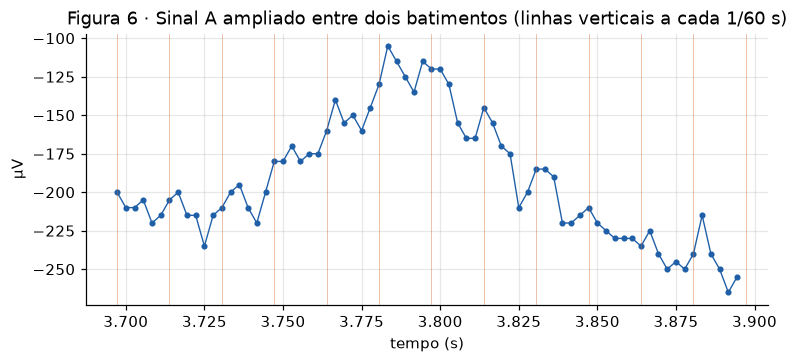

In [ ]:
# Zoom no tempo: um trecho entre dois batimentos do sinal A, onde o ECG é quase plano
i0 = rA[3] + int(0.62 * (rA[4] - rA[3]))
trecho = slice(i0, i0 + int(0.2 * fs))

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(tA[trecho], 1000 * xA[trecho], "o-", color=COR_FILT, ms=3, lw=0.9)
for k in range(13):
    ax.axvline(tA[i0] + k / 60, color=COR_ALT, lw=0.5, alpha=0.5)
ax.set_xlabel("tempo (s)")
ax.set_ylabel("µV")
ax.set_title("Figura 6 · Sinal A ampliado entre dois batimentos (linhas verticais a cada 1/60 s)")
plt.show()

**Figura 6.** Ampliando 0,2 s do sinal A entre dois batimentos e mudando a escala para microvolts, aparece um ziguezague sobreposto à onda lenta. A 360 Hz, um ciclo de 60 Hz ocupa exatamente 6 amostras (as linhas verticais marcam esse período), e o ziguezague tem aproximadamente esse ritmo. Mesmo assim, é difícil afirmar apenas olhando que se trata de uma senoide de 60 Hz: a ondulação é de cerca de ±13 µV, pouco mais que o degrau de quantização do registro (5 µV), e está misturada com ruído.

Esta é a principal lição da Etapa 2: **a informação é a mesma nos dois domínios, mas cada um torna visível uma coisa diferente.** No tempo, a interferência está diluída ao longo de 3600 amostras e quase não se distingue. Na frequência, a FFT soma coerentemente os 600 ciclos de 60 Hz contidos nos 10 s e concentra tudo em um único ponto do espectro, 43 vezes acima do ruído. Com a deriva do sinal B ocorre o contrário: é óbvia no tempo, e o espectro serve para quantificá-la e localizar a frequência de corte adequada.

---
## Etapa 3 · Filtrar e reconstruir (Unidade 3)

### 3.1 A ideia

O espectro mostrou **onde** está cada problema: a interferência do sinal A está concentrada em 60 Hz e a deriva do sinal B está abaixo de 0,5 Hz. Nos dois casos o que queremos preservar (o ECG) ocupa outra região de frequências. Filtrar é então uma operação simples no domínio da frequência: multiplicar o espectro por uma função $H(f)$ que vale perto de 1 onde queremos manter e perto de 0 onde queremos remover, e depois voltar ao tempo com a **Transformada Inversa**:

$$x(t) \xrightarrow{\ \text{FFT}\ } X(f) \xrightarrow{\ \times H(f)\ } Y(f) = H(f)\,X(f) \xrightarrow{\ \text{IFFT}\ } y(t).$$

Comparamos dois tipos de $H(f)$ em cada sinal:

- **Máscara ideal:** $H = 0$ na faixa indesejada e $H = 1$ fora dela. É o filtro mais direto possível, mas não corresponde a nenhum circuito real.
- **Filtro analógico:** $H(f) = H(s)\big|_{s = i 2\pi f}$, a resposta em frequência de um sistema linear descrito por uma equação diferencial. É o filtro que modelamos com Laplace na Etapa 4.

In [ ]:
def filtrar_fft(x, fs, H):
    """Aplica a resposta em frequência H(f) a x: FFT -> multiplica -> IFFT."""
    X = rfft(x)
    f = rfftfreq(len(x), d=1 / fs)
    return irfft(X * H(f), n=len(x))


# Verificação: FFT seguida de IFFT, sem filtro, devolve o sinal original
erro_ida_volta = np.max(np.abs(filtrar_fft(xA, fs, lambda f: np.ones_like(f)) - xA))
print(f"Erro máximo de FFT -> IFFT sem filtro: {erro_ida_volta:.1e} mV")

Erro máximo de FFT -> IFFT sem filtro: 4.2e-16 mV


A ida e volta sem filtro reproduz o sinal com erro da ordem da precisão numérica: a transformada **não perde informação**, apenas muda a forma de representá-la. Toda alteração no sinal filtrado vem, portanto, de $H(f)$.

### 3.2 Projeto dos filtros

**Sinal A, rejeita-faixa (*notch*) em 60 Hz.**

- Máscara ideal: zera as componentes entre 59 Hz e 61 Hz.
- Analógico de 2ª ordem: $H(s) = \dfrac{s^2 + \omega_0^2}{s^2 + \frac{\omega_0}{Q}s + \omega_0^2}$ com $f_0 = 60$ Hz e fator de qualidade $Q = 30$. A largura da faixa rejeitada (a $-3$ dB) é $f_0/Q = 2$ Hz, a mesma da máscara, para que a comparação seja justa.

**Sinal B, passa-altas em 0,5 Hz.**

- Máscara ideal: zera tudo abaixo de 0,5 Hz.
- Analógico de 1ª ordem (circuito RC): $H(s) = \dfrac{s}{s + \omega_c}$ com $f_c = 0{,}5$ Hz.

A frequência de corte de 0,5 Hz fica abaixo da frequência do batimento (acima de 1 Hz), de modo a retirar a deriva sem retirar a fundamental do ECG.

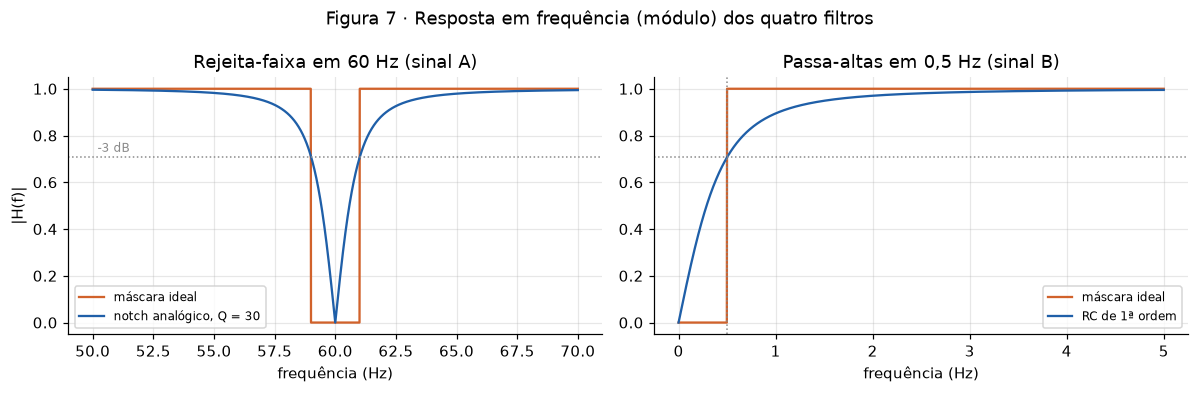

In [ ]:
f0, Q = 60.0, 30.0            # notch
fc = 0.5                      # passa-altas
w0, wc = 2 * np.pi * f0, 2 * np.pi * fc


def H_notch_ideal(f):
    return np.where(np.abs(f - f0) <= f0 / Q / 2, 0.0, 1.0)


def H_notch_analogico(f):
    s = 2j * np.pi * f
    return (s**2 + w0**2) / (s**2 + (w0 / Q) * s + w0**2)


def H_pa_ideal(f):
    return np.where(f < fc, 0.0, 1.0)


def H_pa_rc(f):
    s = 2j * np.pi * f
    return s / (s + wc)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
fn = np.linspace(50, 70, 2001)
ax1.plot(fn, H_notch_ideal(fn), color=COR_ALT, label="máscara ideal")
ax1.plot(fn, np.abs(H_notch_analogico(fn)), color=COR_FILT, label="notch analógico, Q = 30")
ax1.axhline(1 / np.sqrt(2), color=COR_ORIG, ls=":", lw=1)
ax1.text(50.2, 0.73, "-3 dB", fontsize=8, color=COR_ORIG)
ax1.set_xlabel("frequência (Hz)")
ax1.set_ylabel("|H(f)|")
ax1.set_title("Rejeita-faixa em 60 Hz (sinal A)")
ax1.legend(fontsize=8, loc="lower left")
fp = np.linspace(0, 5, 2001)
ax2.plot(fp, H_pa_ideal(fp), color=COR_ALT, label="máscara ideal")
ax2.plot(fp, np.abs(H_pa_rc(fp)), color=COR_FILT, label="RC de 1ª ordem")
ax2.axhline(1 / np.sqrt(2), color=COR_ORIG, ls=":", lw=1)
ax2.axvline(fc, color=COR_ORIG, ls=":", lw=1)
ax2.set_xlabel("frequência (Hz)")
ax2.set_title("Passa-altas em 0,5 Hz (sinal B)")
ax2.legend(fontsize=8, loc="lower right")
fig.suptitle("Figura 7 · Resposta em frequência (módulo) dos quatro filtros")
fig.tight_layout()
plt.show()

**Figura 7.** As máscaras ideais têm transição instantânea entre 0 e 1. Os filtros analógicos têm transição gradual. O *notch* de 2ª ordem ainda é bastante seletivo: vai a zero exatamente em 60 Hz e já recuperou 70,7% do ganho ($-3$ dB) em 59 Hz e 61 Hz. O RC de 1ª ordem é bem menos seletivo: em 0,5 Hz ele deixa passar 70,7%, e ainda atenua cerca de 10% em 1 Hz e 3% em 2 Hz, região onde já existe ECG.

### 3.3 Sinal A: removendo os 60 Hz

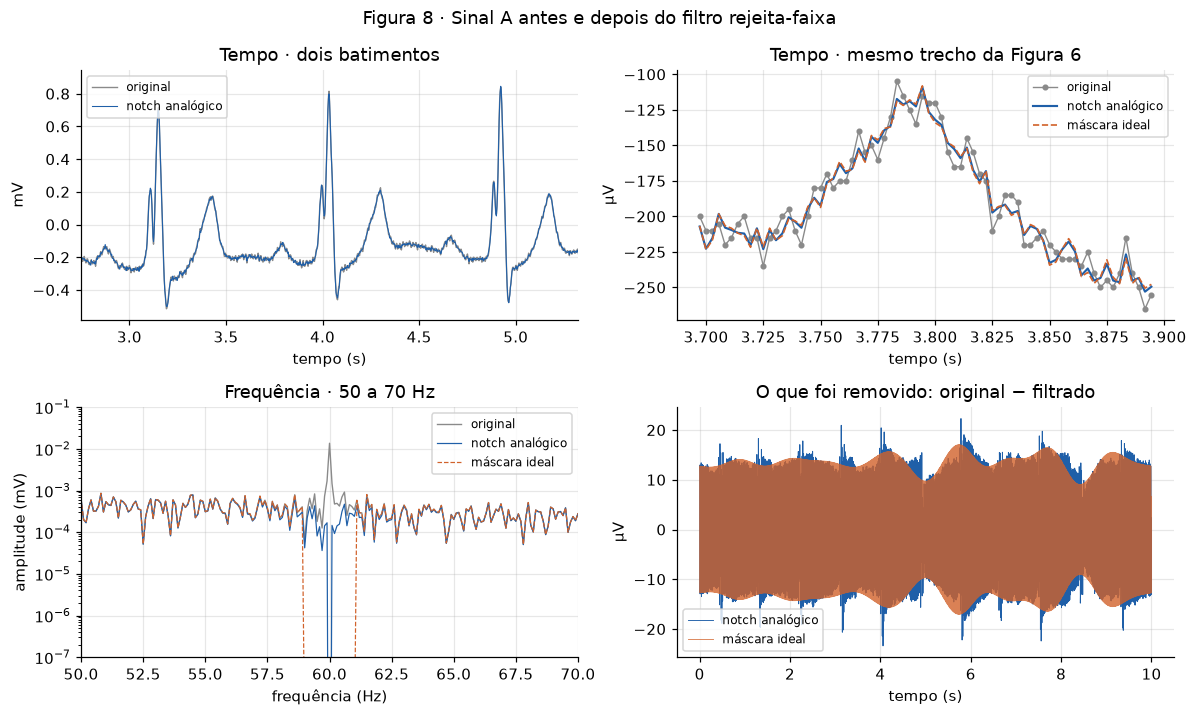

Amplitude do pico em 59-61 Hz: original 13.63 uV | notch 0.471 uV | ideal 0.000 uV
Atenuação do pico com o notch: -29.2 dB
RMS do que foi removido: notch 9.96 uV | ideal 9.88 uV
RMS do sinal original (sem a média): 184 uV
Correlação original x filtrado: notch 0.998540 | ideal 0.998563
Maior diferença entre os dois filtros: 7.99 uV
Maior valor removido junto a um pico R (notch): 23.4 uV; longe dos picos R (mediana do módulo): 8.6 uV


In [ ]:
yA_ideal = filtrar_fft(xA, fs, H_notch_ideal)
yA_notch = filtrar_fft(xA, fs, H_notch_analogico)

_, AA_ideal = espectro(yA_ideal, fs)
_, AA_notch = espectro(yA_notch, fs)

fig, eixos = plt.subplots(2, 2, figsize=(11, 6.6))
ax = eixos[0, 0]
ax.plot(tA, xA, color=COR_ORIG, lw=0.9, label="original")
ax.plot(tA, yA_notch, color=COR_FILT, lw=0.7, label="notch analógico")
ax.set_xlim(tA[rA[3]] - 0.4, tA[rA[5]] + 0.4)
ax.set_xlabel("tempo (s)")
ax.set_ylabel("mV")
ax.set_title("Tempo · dois batimentos")
ax.legend(fontsize=8)

ax = eixos[0, 1]
ax.plot(tA[trecho], 1000 * xA[trecho], "o-", color=COR_ORIG, ms=3, lw=0.9, label="original")
ax.plot(tA[trecho], 1000 * yA_notch[trecho], color=COR_FILT, lw=1.4, label="notch analógico")
ax.plot(tA[trecho], 1000 * yA_ideal[trecho], color=COR_ALT, lw=1.1, ls="--", label="máscara ideal")
ax.set_xlabel("tempo (s)")
ax.set_ylabel("µV")
ax.set_title("Tempo · mesmo trecho da Figura 6")
ax.legend(fontsize=8)

ax = eixos[1, 0]
ax.semilogy(fA, AA, color=COR_ORIG, lw=0.9, label="original")
ax.semilogy(fA, AA_notch, color=COR_FILT, lw=0.8, label="notch analógico")
ax.semilogy(fA, np.maximum(AA_ideal, 1e-9), color=COR_ALT, lw=0.8, ls="--", label="máscara ideal")
ax.set_xlim(50, 70)
ax.set_ylim(1e-7, 1e-1)
ax.set_xlabel("frequência (Hz)")
ax.set_ylabel("amplitude (mV)")
ax.set_title("Frequência · 50 a 70 Hz")
ax.legend(fontsize=8)

ax = eixos[1, 1]
ax.plot(tA, 1000 * (xA - yA_notch), color=COR_FILT, lw=0.6, label="notch analógico")
ax.plot(tA, 1000 * (xA - yA_ideal), color=COR_ALT, lw=0.6, alpha=0.8, label="máscara ideal")
ax.set_xlabel("tempo (s)")
ax.set_ylabel("µV")
ax.set_title("O que foi removido: original − filtrado")
ax.legend(fontsize=8)
fig.suptitle("Figura 8 · Sinal A antes e depois do filtro rejeita-faixa")
fig.tight_layout()
plt.show()


def amp_em(f, A, f1, f2):
    return pico_na_faixa(f, A, f1, f2)[1]


rem_notch, rem_ideal = xA - yA_notch, xA - yA_ideal
print(f"Amplitude do pico em 59-61 Hz: original {1000 * amp_em(fA, AA, 59, 61):.2f} uV | "
      f"notch {1000 * amp_em(fA, AA_notch, 59, 61):.3f} uV | ideal {1000 * amp_em(fA, AA_ideal, 59, 61):.3f} uV")
print(f"Atenuação do pico com o notch: {20 * np.log10(amp_em(fA, AA_notch, 59, 61) / amp_em(fA, AA, 59, 61)):.1f} dB")
print(f"RMS do que foi removido: notch {1000 * rem_notch.std():.2f} uV | ideal {1000 * rem_ideal.std():.2f} uV")
print(f"RMS do sinal original (sem a média): {1000 * xA.std():.0f} uV")
print(f"Correlação original x filtrado: notch {np.corrcoef(xA, yA_notch)[0, 1]:.6f} | ideal {np.corrcoef(xA, yA_ideal)[0, 1]:.6f}")
print(f"Maior diferença entre os dois filtros: {1000 * np.max(np.abs(yA_notch - yA_ideal)):.2f} uV")
print(f"Maior valor removido junto a um pico R (notch): "
      f"{1000 * max(np.max(np.abs(rem_notch[max(i - 20, 0):i + 20])) for i in rA):.1f} uV; "
      f"longe dos picos R (mediana do módulo): {1000 * np.median(np.abs(rem_notch)):.1f} uV")

**Figura 8.**

- **Frequência (embaixo, à esquerda).** A raia de 60 Hz desaparece com os dois filtros. Com o *notch* analógico, a maior amplitude entre 59 e 61 Hz cai de 13,63 µV para 0,47 µV (**−29 dB**), ficando abaixo do patamar de ruído vizinho. Com a máscara ideal vai exatamente a zero, deixando um "buraco" retangular de 2 Hz. Fora dessa faixa as três curvas coincidem: o restante do espectro não foi tocado.
- **Tempo, visão geral (em cima, à esquerda).** Original e filtrado se sobrepõem; a correlação entre eles é 0,9985. A forma dos batimentos (P, QRS, T) está preservada, que é o que se exige de um filtro para ECG.
- **Tempo, zoom (em cima, à direita).** No trecho da Figura 6, o ziguezague de período 1/60 s some e sobra a onda lenta. As duas versões filtradas são quase idênticas.
- **O que foi removido (embaixo, à direita).** A diferença entre original e filtrado é uma oscilação de 60 Hz com cerca de 13 µV de amplitude (RMS de 9,9 µV, o esperado para uma senoide de 13,6 µV: $13{,}6/\sqrt{2} = 9{,}6$). Ou seja, o filtro retirou a interferência identificada na Etapa 2, e praticamente só ela.

**O antes e depois no tempo é discreto**, e isso é uma característica do dado, não uma falha do filtro: neste registro a interferência tem 13,6 µV, contra 184 µV de RMS do ECG. O efeito é claro no espectro e no zoom.

**Diferença entre os dois filtros.** Chega a 8 µV e aparece no gráfico do que foi removido:

- o *notch* analógico apresenta **picos de até 23 µV junto a cada batimento**. O complexo QRS, por ser abrupto, tem um pouco de energia perto de 60 Hz; o filtro reage a cada QRS com uma pequena oscilação amortecida. A Etapa 4 explica esse comportamento pela posição dos polos;
- a máscara ideal não tem esses picos: o que ela remove tem uma envoltória suave, espalhada por todo o trecho, inclusive **antes** de cada batimento. Isso é possível porque ela opera sobre o sinal inteiro de uma vez, algo que nenhum circuito em tempo real consegue fazer.

### 3.4 Sinal B: removendo a deriva da linha de base

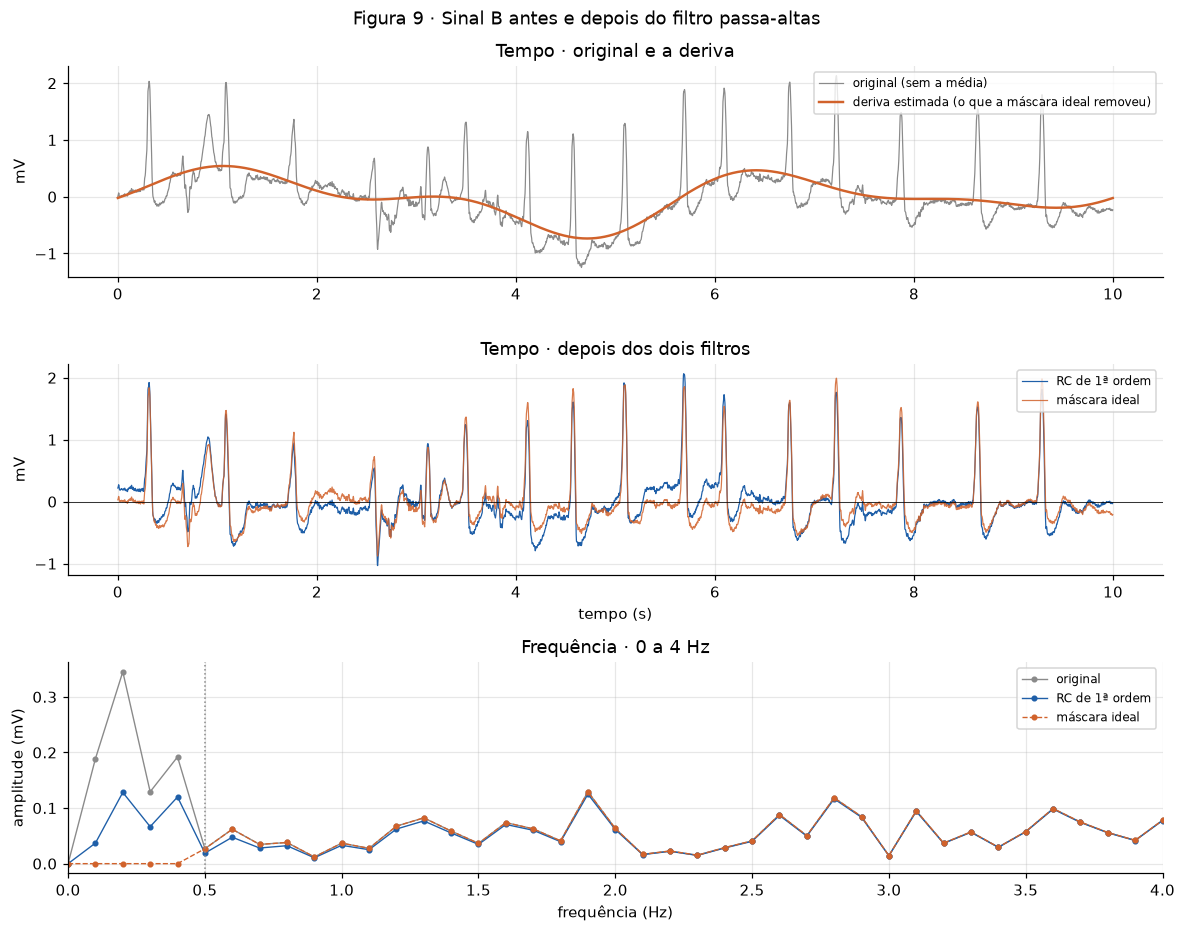

original       excursão da linha de base = 1.325 mV | desvio-padrão = 0.329 mV | energia abaixo de 0,5 Hz = 0.10423 mV²
RC 1ª ordem    excursão da linha de base = 0.567 mV | desvio-padrão = 0.134 mV | energia abaixo de 0,5 Hz = 0.01831 mV²
máscara ideal  excursão da linha de base = 0.287 mV | desvio-padrão = 0.055 mV | energia abaixo de 0,5 Hz = 0.00000 mV²
Componentes de 1 a 40 Hz preservadas (razão de energia): RC 0.9762 | ideal 1.0000
Diferença entre início e fim do trecho original: -0.240 mV


In [ ]:
yB_ideal = filtrar_fft(xB, fs, H_pa_ideal)
yB_rc = filtrar_fft(xB, fs, H_pa_rc)

_, AB_ideal = espectro(yB_ideal, fs)
_, AB_rc = espectro(yB_rc, fs)

fig, eixos = plt.subplots(3, 1, figsize=(11, 8.6))
ax = eixos[0]
ax.plot(tB, xB - xB.mean(), color=COR_ORIG, lw=0.8, label="original (sem a média)")
ax.plot(tB, xB - yB_ideal - xB.mean(), color=COR_ALT, lw=1.6, label="deriva estimada (o que a máscara ideal removeu)")
ax.set_ylabel("mV")
ax.set_title("Tempo · original e a deriva")
ax.legend(fontsize=8, loc="upper right")

ax = eixos[1]
ax.plot(tB, yB_rc, color=COR_FILT, lw=0.8, label="RC de 1ª ordem")
ax.plot(tB, yB_ideal, color=COR_ALT, lw=0.8, alpha=0.85, label="máscara ideal")
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("tempo (s)")
ax.set_ylabel("mV")
ax.set_title("Tempo · depois dos dois filtros")
ax.legend(fontsize=8, loc="upper right")

ax = eixos[2]
ax.plot(fB, AB, "o-", color=COR_ORIG, ms=3, lw=0.9, label="original")
ax.plot(fB, AB_rc, "o-", color=COR_FILT, ms=3, lw=0.9, label="RC de 1ª ordem")
ax.plot(fB, AB_ideal, "o--", color=COR_ALT, ms=3, lw=0.9, label="máscara ideal")
ax.axvline(fc, color=COR_ORIG, ls=":", lw=1)
ax.set_xlim(0, 4)
ax.set_xlabel("frequência (Hz)")
ax.set_ylabel("amplitude (mV)")
ax.set_title("Frequência · 0 a 4 Hz")
ax.legend(fontsize=8)
fig.suptitle("Figura 9 · Sinal B antes e depois do filtro passa-altas")
fig.tight_layout()
plt.show()


def linha_de_base(x, fs):
    """Estimativa da linha de base no tempo: mediana móvel de 0,6 s (independente dos filtros)."""
    return signal.medfilt(x, kernel_size=int(0.6 * fs) | 1)


for nome, y in [("original", xB - xB.mean()), ("RC 1ª ordem", yB_rc), ("máscara ideal", yB_ideal)]:
    lb = linha_de_base(y, fs)
    f_, A_ = espectro(y, fs)
    print(f"{nome:14s} excursão da linha de base = {np.ptp(lb):.3f} mV | desvio-padrão = {lb.std():.3f} mV | "
          f"energia abaixo de 0,5 Hz = {np.sum(A_[(f_ > 0) & (f_ < fc)] ** 2) / 2:.5f} mV²")
m = fB >= 1.0
print(f"Componentes de 1 a 40 Hz preservadas (razão de energia): "
      f"RC {np.sum(AB_rc[(fB >= 1) & (fB < 40)] ** 2) / np.sum(AB[(fB >= 1) & (fB < 40)] ** 2):.4f} | "
      f"ideal {np.sum(AB_ideal[(fB >= 1) & (fB < 40)] ** 2) / np.sum(AB[(fB >= 1) & (fB < 40)] ** 2):.4f}")
print(f"Diferença entre início e fim do trecho original: {xB[-1] - xB[0]:+.3f} mV")

**Figura 9.**

- **Em cima.** A curva laranja é a parte do sinal abaixo de 0,5 Hz, isto é, o que a máscara ideal retirou. Ela acompanha a subida e descida da linha de base do original: a deriva foi corretamente isolada.
- **No meio.** Depois de filtrados, os batimentos passam a oscilar em torno de zero. Para medir isso sem depender dos próprios filtros, estimamos a linha de base no tempo com uma mediana móvel de 0,6 s: a excursão dela cai de **1,33 mV** no original para **0,57 mV** com o RC e **0,29 mV** com a máscara ideal.
- **Embaixo.** Abaixo de 0,5 Hz, a máscara ideal zera tudo e o RC apenas reduz. Acima de 1 Hz as três curvas praticamente coincidem.

**Por que o RC de 1ª ordem remove menos.** Seu ganho cresce devagar com a frequência. Em 0,2 Hz, onde está a maior componente da deriva, $|H| = 0{,}2/\sqrt{0{,}2^2 + 0{,}5^2} = 0{,}37$: ele ainda deixa passar 37% dela (0,345 mV vira 0,128 mV, como se lê no gráfico). No total, a energia abaixo de 0,5 Hz cai 82%, não 100%. Em compensação ele quase não mexe no ECG: preserva 97,6% da energia entre 1 e 40 Hz.

**Limitações que observamos.**

- Mesmo com a máscara ideal sobra alguma flutuação (0,29 mV). Parte do que parece deriva neste sinal está acima de 0,5 Hz e se confunde com o próprio ECG, que é irregular. Subir a frequência de corte removeria mais deriva, mas começaria a distorcer as ondas lentas do batimento (onda T, segmento ST). É um compromisso.
- A filtragem por FFT trata o trecho como se ele se repetisse periodicamente. Como o sinal B termina 0,24 mV abaixo de onde começa, essa repetição cria um degrau artificial na emenda, e é por isso que a saída do RC começa em cerca de +0,25 mV em vez de partir de zero. O efeito fica restrito às bordas do trecho.

### 3.5 Resumo da comparação



| | Máscara ideal | Filtro analógico |
|---|---|---|
| Remoção da faixa indesejada | total | *notch*: −29 dB na raia de 60 Hz; RC: −82% da energia abaixo de 0,5 Hz |
| Efeito fora da faixa | nenhum | *notch*: desprezível; RC: perde 2,4% da energia de 1 a 40 Hz |
| Efeito colateral no tempo | age sobre o trecho inteiro, antes e depois de cada evento | oscilação amortecida depois de cada QRS (*notch*) |
| Pode ser construído como circuito e operar em tempo real? | não: precisa do sinal completo | sim: é uma equação diferencial |
| Descrição matemática | uma tabela de zeros e uns | uma função de transferência $H(s)$ com poucos parâmetros |

Para um trecho já gravado, a máscara ideal dá o melhor resultado numérico. O filtro analógico é o que pode existir dentro de um eletrocardiógrafo, e é ele que modelamos a seguir. Para a interferência de 60 Hz (estreita e bem localizada), o filtro de 2ª ordem já é praticamente tão bom quanto o ideal. Para a deriva, o de 1ª ordem é visivelmente inferior, por ter transição muito gradual.

---
## Etapa 4 · O filtro como sistema linear (Unidade 4)

Na Etapa 3 os filtros analógicos apareceram como fórmulas $H(s)$ prontas. Agora mostramos de onde elas vêm: cada filtro é um **sistema linear e invariante no tempo**, descrito por uma equação diferencial, e a Transformada de Laplace

$$\mathcal{L}\{x(t)\} = X(s) = \int_0^{\infty} x(t)\,e^{-st}\,dt, \qquad s = \sigma + i\omega,$$

transforma essa equação diferencial em uma equação algébrica, graças à propriedade $\mathcal{L}\{y'(t)\} = sY(s) - y(0)$. Com condições iniciais nulas, a razão entre saída e entrada é a **função de transferência** $H(s) = Y(s)/X(s)$.

### 4.1 Aquecimento: o circuito RC de 1ª ordem

Um resistor $R$ em série com um capacitor $C$, com a saída medida no capacitor, obedece a

$$RC\,\frac{dy}{dt} + y(t) = x(t).$$

In [ ]:
s = sp.symbols("s")
t = sp.symbols("t", positive=True)
R, C = sp.symbols("R C", positive=True)
X, Y = sp.symbols("X Y")

# Laplace da equação diferencial com y(0) = 0:  RC*s*Y + Y = X
H_rc = sp.simplify(sp.solve(sp.Eq(R * C * s * Y + Y, X), Y)[0] / X)
display(sp.Eq(sp.Symbol("H_{RC}(s)"), H_rc))

polo_rc = sp.solve(sp.denom(sp.together(H_rc)), s)
print("Polo:", polo_rc)

# Resposta ao impulso h(t) = L^-1{H(s)} e conferência pelo caminho inverso
h_rc = sp.inverse_laplace_transform(H_rc, s, t)
display(sp.Eq(sp.Symbol("h(t)"), sp.simplify(h_rc)))
volta = sp.laplace_transform(sp.exp(-t / (R * C)) / (R * C), t, s, noconds=True)
print("L{ e^(-t/RC) / RC } == H(s) ?", sp.simplify(volta - H_rc) == 0)

# Resposta ao degrau: L^-1{ H(s) / s }
degrau_rc = sp.simplify(sp.inverse_laplace_transform(H_rc / s, s, t))
display(sp.Eq(sp.Symbol("y_{degrau}(t)"), degrau_rc))

Polo: [-1/(C*R)]


L{ e^(-t/RC) / RC } == H(s) ? True


O resultado é $H_{RC}(s) = \dfrac{1}{RCs + 1}$, um **passa-baixas** de 1ª ordem.

- Tem um único **polo**, em $s = -\dfrac{1}{RC}$: real e negativo.
- A resposta ao impulso é $h(t) = \dfrac{1}{RC}e^{-t/RC}$. O polo aparece no expoente: um polo em $s = p$ gera um termo $e^{pt}$ na resposta. Como $p < 0$, esse termo decai, e o sistema é **estável**.
- A resposta ao degrau, $1 - e^{-t/RC}$, é a conhecida carga do capacitor, com constante de tempo $\tau = RC = 1/|p|$.

Com isso temos a regra geral usada no restante da etapa: **o sistema é estável se, e somente se, todos os polos têm parte real negativa** (ficam no semiplano esquerdo), pois só então todos os termos $e^{pt}$ decaem.

### 4.2 O passa-altas RC usado no sinal B

Trocando a posição da saída para o resistor, a equação passa a ser $\dfrac{dy}{dt} + \omega_c\,y(t) = \dfrac{dx}{dt}$, com $\omega_c = \dfrac{1}{RC}$.

In [ ]:
wc_, w0_, Q_ = sp.symbols("omega_c omega_0 Q", positive=True)

# Laplace com condições iniciais nulas:  s*Y + wc*Y = s*X
H_pa = sp.simplify(sp.solve(sp.Eq(s * Y + wc_ * Y, s * X), Y)[0] / X)
display(sp.Eq(sp.Symbol("H_{PA}(s)"), H_pa))
print("Zeros:", sp.solve(sp.numer(sp.together(H_pa)), s), "  Polos:", sp.solve(sp.denom(sp.together(H_pa)), s))

RC_valor = 1 / wc
print(f"\nPara fc = {fc} Hz: wc = {wc:.4f} rad/s, RC = {RC_valor:.4f} s "
      f"(por exemplo R = {RC_valor / 1e-6 / 1e3:.0f} kOhm com C = 1 uF)")

Zeros: [0]   Polos: [-omega_c]

Para fc = 0.5 Hz: wc = 3.1416 rad/s, RC = 0.3183 s (por exemplo R = 318 kOhm com C = 1 uF)


$H_{PA}(s) = \dfrac{s}{s + \omega_c}$ tem um **zero** em $s = 0$ e um **polo** em $s = -\omega_c = -\pi \approx -3{,}14$ rad/s.

### 4.3 O rejeita-faixa (*notch*) usado no sinal A

O *notch* de 2ª ordem (por exemplo, um circuito RLC série com a saída medida sobre o conjunto LC) é descrito por

$$\frac{d^2y}{dt^2} + \frac{\omega_0}{Q}\frac{dy}{dt} + \omega_0^2\,y(t) = \frac{d^2x}{dt^2} + \omega_0^2\,x(t).$$

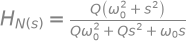

Zeros:


Polos:


In [ ]:
# Laplace com condições iniciais nulas: (s^2 + (w0/Q) s + w0^2) Y = (s^2 + w0^2) X
H_n = sp.simplify(sp.solve(sp.Eq((s**2 + w0_ / Q_ * s + w0_**2) * Y, (s**2 + w0_**2) * X), Y)[0] / X)
display(sp.Eq(sp.Symbol("H_N(s)"), H_n))

num_n, den_n = sp.fraction(sp.together(H_n))
zeros_n = sp.solve(num_n, s)
polos_n = sp.solve(den_n, s)
print("Zeros:")
display(zeros_n)
print("Polos:")
display([sp.simplify(p) for p in polos_n])

$$H_N(s) = \frac{s^2 + \omega_0^2}{s^2 + \frac{\omega_0}{Q}s + \omega_0^2}$$

- **Zeros** em $s = \pm i\,\omega_0$: exatamente **sobre o eixo imaginário**.
- **Polos** em $s = -\dfrac{\omega_0}{2Q} \pm i\,\omega_0\sqrt{1 - \dfrac{1}{4Q^2}}$: um par complexo conjugado, logo à esquerda dos zeros (para $Q > 1/2$).

### 4.4 Mapas de polos e zeros

Agora com os valores numéricos usados na Etapa 3, calculados pelo `scipy.signal`.

--- Notch 60 Hz (Q = 30) ---
  zeros (rad/s): [-0.+376.991j  0.-376.991j]
  polos (rad/s): [-6.283+376.939j -6.283-376.939j]
  polos em Hz (parte imaginária / 2 pi): [ 59.992 -59.992]
  maior parte real dos polos: -6.283 -> ESTÁVEL
--- Passa-altas RC 0,5 Hz ---
  zeros (rad/s): [0.]
  polos (rad/s): [-3.142]
  polos em Hz (parte imaginária / 2 pi): [0.]
  maior parte real dos polos: -3.142 -> ESTÁVEL


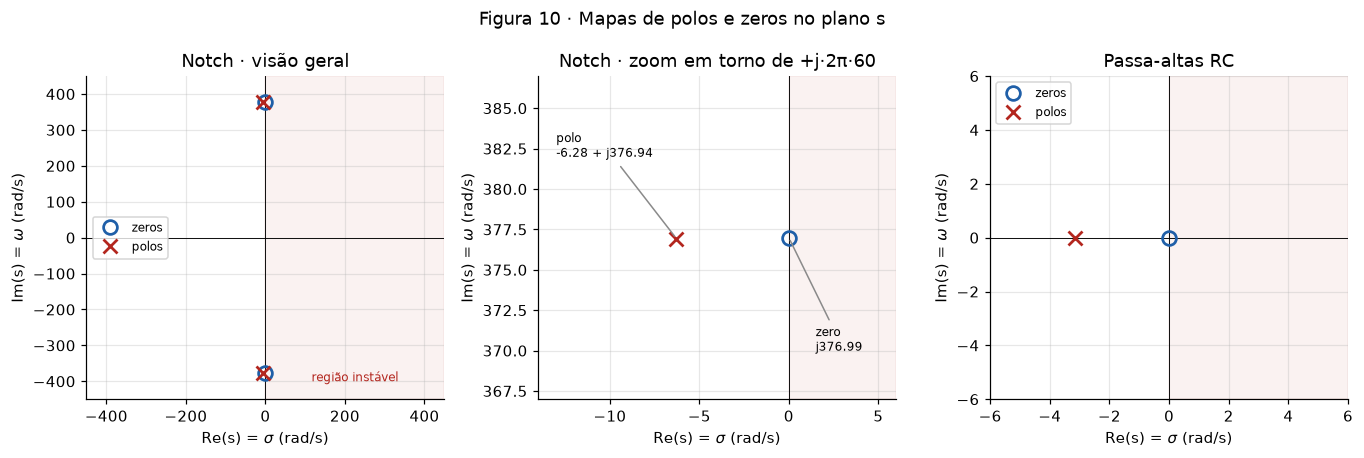

In [ ]:
sis_notch = signal.TransferFunction([1, 0, w0**2], [1, w0 / Q, w0**2])
sis_pa = signal.TransferFunction([1, 0], [1, wc])

for nome, sis in [("Notch 60 Hz (Q = 30)", sis_notch), ("Passa-altas RC 0,5 Hz", sis_pa)]:
    print(f"--- {nome} ---")
    print("  zeros (rad/s):", np.round(sis.zeros, 3))
    print("  polos (rad/s):", np.round(sis.poles, 3))
    print("  polos em Hz (parte imaginária / 2 pi):", np.round(sis.poles.imag / (2 * np.pi), 3))
    print("  maior parte real dos polos:", f"{sis.poles.real.max():.3f}",
          "-> ESTÁVEL" if sis.poles.real.max() < 0 else "-> INSTÁVEL")


def mapa_polos_zeros(ax, sis, titulo):
    ax.axhline(0, color="k", lw=0.6)
    ax.axvline(0, color="k", lw=0.6)
    ax.plot(sis.zeros.real, sis.zeros.imag, "o", ms=9, mfc="none", mec=COR_FILT, mew=1.8, label="zeros")
    ax.plot(sis.poles.real, sis.poles.imag, "x", ms=9, color=COR_DEST, mew=1.8, label="polos")
    ax.set_xlabel(r"Re(s) = $\sigma$ (rad/s)")
    ax.set_ylabel(r"Im(s) = $\omega$ (rad/s)")
    ax.set_title(titulo)


fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12.5, 4.2))
mapa_polos_zeros(ax1, sis_notch, "Notch · visão geral")
ax1.set_xlim(-450, 450)
ax1.set_ylim(-450, 450)
ax1.axvspan(0, 450, color=COR_DEST, alpha=0.06)
ax1.text(225, -400, "região instável", color=COR_DEST, ha="center", fontsize=8)
ax1.legend(fontsize=8, loc="center left")

mapa_polos_zeros(ax2, sis_notch, "Notch · zoom em torno de +j·2π·60")
ax2.set_xlim(-14, 6)
ax2.set_ylim(w0 - 10, w0 + 10)
ax2.axvspan(0, 6, color=COR_DEST, alpha=0.06)
ax2.annotate(f"polo\n{sis_notch.poles.real[0]:.2f} + j{abs(sis_notch.poles.imag[0]):.2f}",
             (sis_notch.poles.real[0], abs(sis_notch.poles.imag[0])), xytext=(-13, w0 + 5), fontsize=8,
             arrowprops=dict(arrowstyle="-", color=COR_ORIG))
ax2.annotate(f"zero\nj{w0:.2f}", (0, w0), xytext=(1.5, w0 - 7), fontsize=8,
             arrowprops=dict(arrowstyle="-", color=COR_ORIG))

mapa_polos_zeros(ax3, sis_pa, "Passa-altas RC")
ax3.set_xlim(-6, 6)
ax3.set_ylim(-6, 6)
ax3.axvspan(0, 6, color=COR_DEST, alpha=0.06)
ax3.legend(fontsize=8, loc="upper left")
fig.suptitle("Figura 10 · Mapas de polos e zeros no plano s")
fig.tight_layout()
plt.show()

**Figura 10.**

- **Notch.** Os dois **zeros** estão em $s = \pm j\,376{,}99$ rad/s, exatamente sobre o eixo imaginário, em $\pm 2\pi\cdot 60$. Os dois **polos** estão em $s = -6{,}28 \pm j\,376{,}94$ rad/s: praticamente na mesma altura dos zeros, deslocados 6,28 rad/s para a esquerda. Na visão geral, polo e zero ficam tão próximos que se sobrepõem; só o zoom os separa.
- **Passa-altas.** Um zero na origem e um polo real em $s = -3{,}14$ rad/s.

**Estabilidade.** Todos os polos têm parte real negativa (−6,28 e −3,14 rad/s), portanto estão no semiplano esquerdo e **os dois sistemas são estáveis**: qualquer perturbação na saída desaparece com o tempo. Os zeros sobre o eixo imaginário não afetam a estabilidade, que depende só dos polos.

**O que os zeros fazem.** Um zero em $s = j\omega_z$ significa $H(j\omega_z) = 0$: uma senoide exatamente nessa frequência não passa. O *notch* tem zeros em $\pm j2\pi\cdot 60$, e por isso bloqueia 60 Hz. O passa-altas tem um zero em $s = 0$, e por isso bloqueia a frequência zero (o nível constante) e atenua as frequências próximas dela.

### 4.5 Estabilidade vista no tempo

A posição dos polos prevê como o sistema responde a um impulso. Conferimos com a resposta ao impulso calculada pelo `scipy` (sem a parcela impulsiva $\delta(t)$, que aparece porque numerador e denominador têm o mesmo grau).

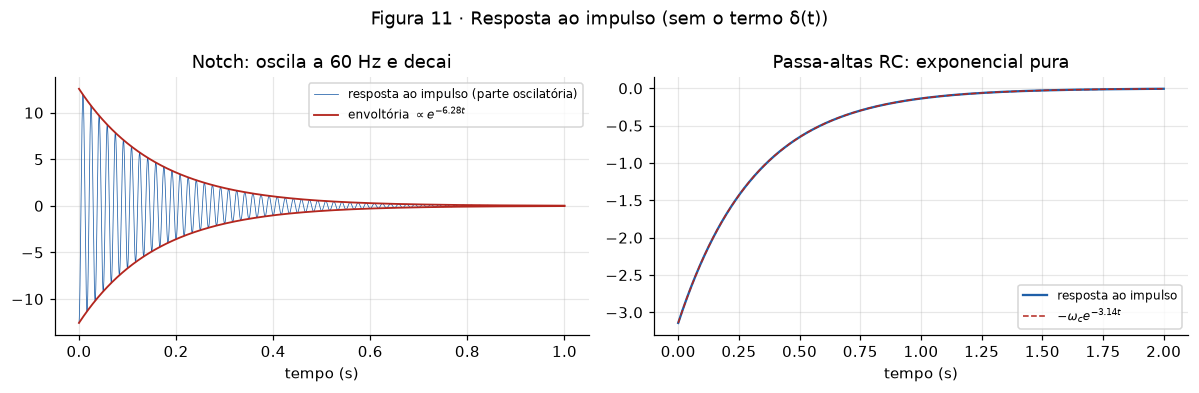

Notch: Re(polo) = -6.283 rad/s -> constante de tempo = 159 ms; Im(polo) = 376.94 rad/s = 59.992 Hz
Passa-altas: polo = -3.142 rad/s -> constante de tempo = 318 ms


In [ ]:
sigma_n = sis_notch.poles.real[0]
sigma_pa = sis_pa.poles.real[0]

# H(s) = 1 + G(s): G é a parte estritamente própria, cuja resposta ao impulso é uma função comum
G_notch = signal.TransferFunction([-(w0 / Q), 0], [1, w0 / Q, w0**2])
G_pa = signal.TransferFunction([-wc], [1, wc])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
ti, hi = signal.impulse(G_notch, T=np.linspace(0, 1.0, 20001))
ax1.plot(ti, hi, color=COR_FILT, lw=0.5, label="resposta ao impulso (parte oscilatória)")
ax1.plot(ti, (w0 / Q) * np.exp(sigma_n * ti), color=COR_DEST, lw=1.2, label=rf"envoltória $\propto e^{{{sigma_n:.2f}t}}$")
ax1.plot(ti, -(w0 / Q) * np.exp(sigma_n * ti), color=COR_DEST, lw=1.2)
ax1.set_xlabel("tempo (s)")
ax1.set_title("Notch: oscila a 60 Hz e decai")
ax1.legend(fontsize=8)

ti2, hi2 = signal.impulse(G_pa, T=np.linspace(0, 2.0, 2001))
ax2.plot(ti2, hi2, color=COR_FILT, label="resposta ao impulso")
ax2.plot(ti2, -wc * np.exp(sigma_pa * ti2), color=COR_DEST, ls="--", lw=1, label=rf"$-\omega_c e^{{{sigma_pa:.2f}t}}$")
ax2.set_xlabel("tempo (s)")
ax2.set_title("Passa-altas RC: exponencial pura")
ax2.legend(fontsize=8)
fig.suptitle("Figura 11 · Resposta ao impulso (sem o termo δ(t))")
fig.tight_layout()
plt.show()

print(f"Notch: Re(polo) = {sigma_n:.3f} rad/s -> constante de tempo = {1 / abs(sigma_n) * 1000:.0f} ms; "
      f"Im(polo) = {abs(sis_notch.poles.imag[0]):.2f} rad/s = {abs(sis_notch.poles.imag[0]) / (2 * np.pi):.3f} Hz")
print(f"Passa-altas: polo = {sigma_pa:.3f} rad/s -> constante de tempo = {1 / abs(sigma_pa) * 1000:.0f} ms")

**Figura 11.** A posição dos polos descreve a resposta no tempo:

- **Parte imaginária = frequência de oscilação.** Os polos do *notch* têm parte imaginária de 376,94 rad/s, isto é, 59,99 Hz: a resposta ao impulso oscila a essa frequência. O polo do passa-altas é real, e sua resposta não oscila.
- **Parte real = velocidade de decaimento.** A envoltória do *notch* é $e^{-6{,}28t}$, com constante de tempo $1/6{,}28 = 159$ ms; a oscilação leva cerca de 0,8 s para desaparecer. No passa-altas a resposta é $-\omega_c e^{-3{,}14t}$, com constante de tempo de 318 ms.

Isso explica o efeito colateral visto na Figura 8. Cada complexo QRS funciona como um pequeno impulso na entrada do *notch*, e o filtro responde com uma oscilação de 60 Hz que decai em algumas centenas de milissegundos: são os picos junto a cada batimento. Fica visível também o compromisso de projeto. Aumentar $Q$ aproxima os polos do eixo imaginário, o que estreita a faixa rejeitada, mas faz a oscilação durar mais. Se os polos chegassem ao eixo ($Q \to \infty$), a oscilação não decairia; se o atravessassem, cresceria sem limite e o sistema seria instável.

### 4.6 A conexão com a Etapa 2: do plano s para o espectro

A resposta em frequência que multiplicou o espectro na Etapa 3 **é** a função de transferência avaliada sobre o eixo imaginário:

$$H(f) = H(s)\Big|_{s = i 2\pi f}.$$

Ou seja, a FFT "enxerga" apenas o corte de $|H(s)|$ ao longo da reta $\sigma = 0$. O gráfico abaixo mostra a superfície $|H_N(s)|$ em torno do polo superior e, ao lado, esse corte sobreposto ao espectro do sinal A.

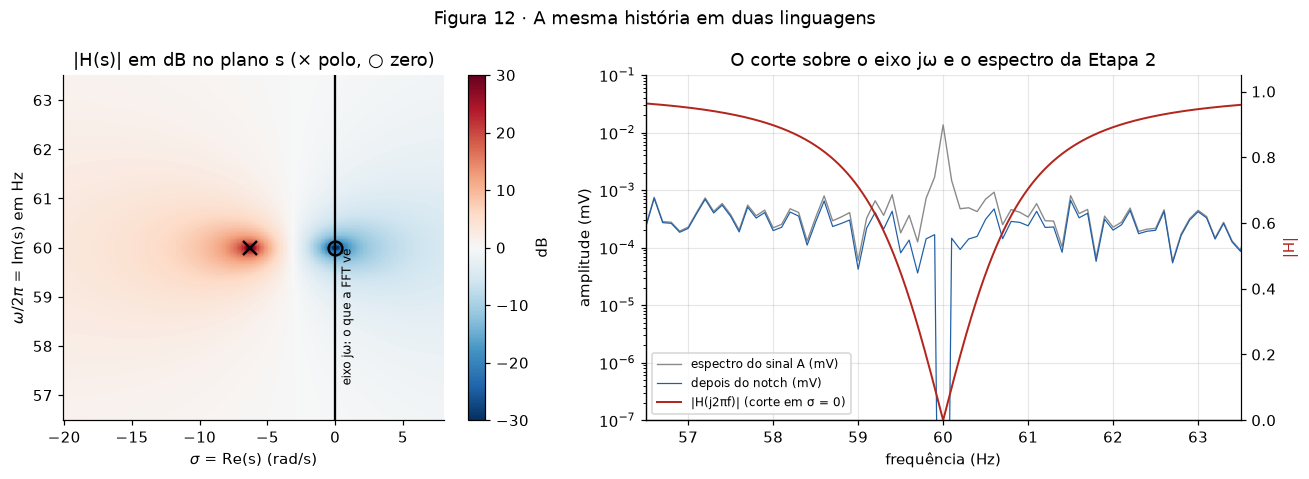

scipy.signal.freqs(H(s)) x H(f) da Etapa 3: diferença máxima = 0.0e+00
|H| em 60 Hz = 0.00e+00
Faixa rejeitada a -3 dB: 59.01 a 61.01 Hz -> largura 2.00 Hz
Previsão pelos polos: 2*|Re(polo)| / (2 pi) = 2.00 Hz  (= f0/Q = 2.00 Hz)
f =  10.0 Hz: distâncias aos zeros / distâncias aos polos = 1.0000   |H| = 1.0000
f =  59.0 Hz: distâncias aos zeros / distâncias aos polos = 0.7101   |H| = 0.7101
f =  60.0 Hz: distâncias aos zeros / distâncias aos polos = 0.0000   |H| = 0.0000
f =  61.0 Hz: distâncias aos zeros / distâncias aos polos = 0.7042   |H| = 0.7042


In [ ]:
def H_notch_s(s_):
    return (s_**2 + w0**2) / (s_**2 + (w0 / Q) * s_ + w0**2)


sig = np.linspace(-20, 8, 281)
om = np.linspace(w0 - 22, w0 + 22, 441)
S, W = np.meshgrid(sig, om)
modulo_dB = 20 * np.log10(np.abs(H_notch_s(S + 1j * W)) + 1e-12)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1, 1.25]})
im = ax1.pcolormesh(S, W / (2 * np.pi), modulo_dB, cmap="RdBu_r", vmin=-30, vmax=30, shading="auto")
ax1.axvline(0, color="k", lw=1.5)
ax1.text(0.4, 57.2, "eixo jω: o que a FFT vê", rotation=90, fontsize=8, va="bottom")
ax1.plot(0, f0, "o", ms=9, mfc="none", mec="k", mew=1.6)
ax1.plot(sis_notch.poles.real[0], abs(sis_notch.poles.imag[0]) / (2 * np.pi), "x", ms=9, color="k", mew=1.6)
ax1.set_xlabel(r"$\sigma$ = Re(s) (rad/s)")
ax1.set_ylabel(r"$\omega / 2\pi$ = Im(s) em Hz")
ax1.set_title("|H(s)| em dB no plano s (× polo, ○ zero)")
ax1.grid(False)
fig.colorbar(im, ax=ax1, label="dB")

ax2.semilogy(fA, AA, color=COR_ORIG, lw=0.9, label="espectro do sinal A (mV)")
ax2.semilogy(fA, AA_notch, color=COR_FILT, lw=0.8, label="depois do notch (mV)")
ax2.set_xlim(56.5, 63.5)
ax2.set_ylim(1e-7, 1e-1)
ax2.set_xlabel("frequência (Hz)")
ax2.set_ylabel("amplitude (mV)")
ax2b = ax2.twinx()
ff = np.linspace(56.5, 63.5, 4001)
ax2b.plot(ff, np.abs(H_notch_s(2j * np.pi * ff)), color=COR_DEST, lw=1.3, label="|H(j2πf)| (corte em σ = 0)")
ax2b.set_ylabel("|H|", color=COR_DEST)
ax2b.set_ylim(0, 1.05)
ax2b.grid(False)
ax2b.spines["right"].set_visible(True)
linhas = ax2.get_lines() + ax2b.get_lines()
ax2.legend(linhas, [l.get_label() for l in linhas], fontsize=8, loc="lower left")
ax2.set_title("O corte sobre o eixo jω e o espectro da Etapa 2")
fig.suptitle("Figura 12 · A mesma história em duas linguagens")
fig.tight_layout()
plt.show()

# Conferências numéricas da conexão
_, Hs = signal.freqs(sis_notch.num, sis_notch.den, worN=2 * np.pi * fA[1:])
print(f"scipy.signal.freqs(H(s)) x H(f) da Etapa 3: diferença máxima = {np.max(np.abs(Hs - H_notch_analogico(fA[1:]))):.1e}")
print(f"|H| em 60 Hz = {abs(H_notch_s(2j * np.pi * 60.0)):.2e}")
mod = np.abs(H_notch_s(2j * np.pi * ff))
faixa = ff[mod < 1 / np.sqrt(2)]
print(f"Faixa rejeitada a -3 dB: {faixa.min():.2f} a {faixa.max():.2f} Hz -> largura {np.ptp(faixa):.2f} Hz")
print(f"Previsão pelos polos: 2*|Re(polo)| / (2 pi) = {2 * abs(sigma_n) / (2 * np.pi):.2f} Hz  (= f0/Q = {f0 / Q:.2f} Hz)")

# Interpretação geométrica: |H(jw)| = produto das distâncias aos zeros / produto das distâncias aos polos
for f_teste in [10.0, 59.0, 60.0, 61.0]:
    p = 2j * np.pi * f_teste
    geo = np.prod(np.abs(p - sis_notch.zeros)) / np.prod(np.abs(p - sis_notch.poles))
    print(f"f = {f_teste:5.1f} Hz: distâncias aos zeros / distâncias aos polos = {geo:.4f}   |H| = {abs(H_notch_s(p)):.4f}")

**Figura 12.**

- **À esquerda**, o módulo de $H_N(s)$ no plano $s$, em torno de $+j2\pi\cdot 60$. O polo é um pico (vermelho) e o zero é um poço (azul). A linha preta é o eixo imaginário, o único caminho que a FFT percorre.
- **À direita**, o que se encontra ao caminhar por essa linha: a curva vermelha $|H(j2\pi f)|$, que vale quase 1 longe de 60 Hz e desce a zero ao passar sobre o zero. No mesmo gráfico estão o espectro do sinal A da Etapa 2 (cinza) e o espectro filtrado (azul).

**A conexão.** Na Etapa 2 encontramos uma raia estreita em 60,0 Hz. Na linguagem de Laplace, eliminar essa raia é **colocar um zero do sistema em $s = j2\pi\cdot 60$**, o ponto do eixo imaginário que corresponde àquela frequência. A raia do espectro e o zero do mapa estão no mesmo lugar, e por isso ela desaparece.

Os polos controlam o resto da curva. Geometricamente, $|H(j\omega)|$ é o produto das distâncias do ponto $j\omega$ aos zeros dividido pelo produto das distâncias aos polos (conferido numericamente acima):

- **longe de 60 Hz** (por exemplo, 10 Hz), o polo e o zero estão tão próximos um do outro que as distâncias até eles são praticamente iguais: a razão é 1,0000 e o ECG passa inalterado;
- **perto de 60 Hz**, a distância ao zero vai a zero enquanto a distância ao polo nunca fica menor que 6,28 rad/s: a razão despenca;
- **a largura do vale** é fixada pela distância do polo ao eixo. A faixa a −3 dB medida na curva é de 59,01 a 61,01 Hz, **2,00 Hz**, exatamente $2|\mathrm{Re}(p)|/2\pi = f_0/Q$.

O mesmo vale para o passa-altas: o zero na origem derruba as frequências próximas de 0 Hz, onde a Etapa 2 mostrou a deriva do sinal B, e o polo em −3,14 rad/s define onde o ganho se recupera ($|H| = 0{,}707$ em $\omega = 3{,}14$ rad/s, isto é, 0,5 Hz). Como esse polo fica relativamente longe do zero, a recuperação é lenta, e daí a transição gradual que limitou o resultado na Figura 9.

É a mesma história contada em duas linguagens: o espectro diz **o que há no sinal** em cada frequência; o mapa de polos e zeros diz **o que o sistema faz** com cada frequência.

### 4.7 Conferência: simulando o sistema no tempo

Como última verificação, resolvemos a equação diferencial do *notch* diretamente no tempo (`scipy.signal.lsim`, partindo do repouso) e comparamos com o resultado da Etapa 3, obtido por FFT → $H$ → IFFT.

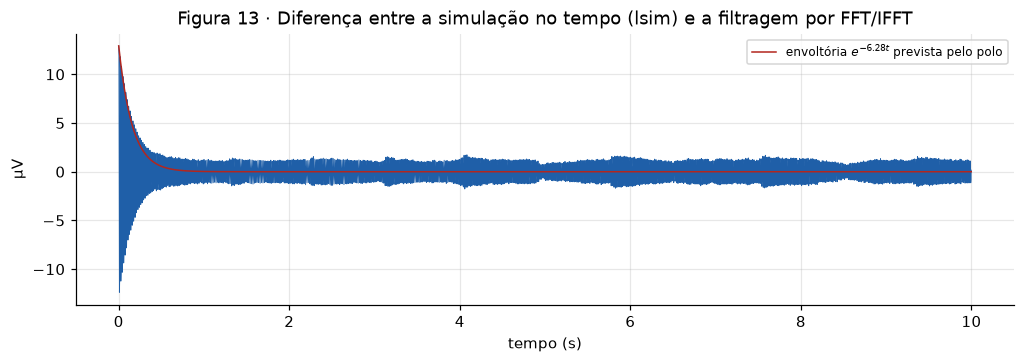

Diferença máxima no primeiro 0,5 s: 12.92 uV
Diferença máxima de 2 s em diante:  1.770 uV


In [ ]:
entrada = xA - xA.mean()
_, yA_lsim, _ = signal.lsim(sis_notch, U=entrada, T=tA)
dif = (yA_lsim - (yA_notch - yA_notch.mean())) * 1000

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(tA, dif, color=COR_FILT, lw=0.6)
ax.plot(tA, np.max(np.abs(dif[:60])) * np.exp(sigma_n * (tA - tA[0])), color=COR_DEST, lw=1,
        label=rf"envoltória $e^{{{sigma_n:.2f}t}}$ prevista pelo polo")
ax.set_xlabel("tempo (s)")
ax.set_ylabel("µV")
ax.set_title("Figura 13 · Diferença entre a simulação no tempo (lsim) e a filtragem por FFT/IFFT")
ax.legend(fontsize=8)
plt.show()

print(f"Diferença máxima no primeiro 0,5 s: {np.max(np.abs(dif[:fs // 2])):.2f} uV")
print(f"Diferença máxima de 2 s em diante:  {np.max(np.abs(dif[2 * fs:])):.3f} uV")

**Figura 13.** A diferença entre os dois métodos começa em cerca de 13 µV e decai seguindo a envoltória $e^{-6{,}28t}$ prevista pelo polo. Isso é o **transitório** do sistema: a simulação no tempo parte do repouso e leva algumas constantes de tempo para "entrar em regime", enquanto a filtragem por FFT trata o trecho como periódico e fornece diretamente a resposta em regime permanente. A parte real do polo, lida no mapa da Figura 10, é exatamente a taxa com que as duas soluções se aproximam.

Depois de 2 s resta uma diferença de até 1,8 µV que não decai. Atribuímos esse resíduo ao fato de os dois métodos fazerem hipóteses diferentes sobre o sinal entre uma amostra e outra (o `lsim` liga as amostras por segmentos de reta; a FFT supõe um sinal de banda limitada), o que pesa perto de 60 Hz, onde há apenas 6 amostras por ciclo. É um valor pequeno diante dos 13,6 µV da interferência removida.

---
## Conclusão

Partimos de dois trechos reais de ECG e percorremos os quatro temas da disciplina:

1. **Série de Fourier.** A onda quadrada tem apenas harmônicos ímpares, $b_n = 4/(n\pi)$, ou $c_n = -2i/(n\pi)$ na forma complexa. A aproximação converge em média quadrática ($E_N \propto 1/N$), mas o pico de Gibbs junto ao salto permanece em 9% da altura do salto para qualquer $N$.
2. **Espectro.** A FFT mostrou que o ECG regular é, na prática, uma série de Fourier com fundamental na frequência cardíaca (1,1 Hz), e localizou os dois problemas: uma raia de 13,6 µV em 60 Hz no sinal A, invisível no tempo, e uma deriva abaixo de 0,5 Hz com 37,5% da energia no sinal B.
3. **Filtragem.** Multiplicar o espectro por $H(f)$ e aplicar a transformada inversa removeu a raia de 60 Hz (−29 dB com o *notch*) e reduziu a excursão da linha de base de 1,33 mV para 0,57 mV (RC) ou 0,29 mV (máscara ideal), preservando a forma dos batimentos.
4. **Laplace.** Os filtros analógicos são equações diferenciais cujas funções de transferência têm todos os polos no semiplano esquerdo (estáveis). Os zeros do *notch* em $\pm j2\pi\cdot 60$ coincidem com a raia encontrada na Etapa 2, e a distância dos polos ao eixo imaginário determina tanto a largura da faixa rejeitada (2 Hz) quanto a duração da oscilação no tempo (159 ms).

**Limitações.** A interferência de 60 Hz do registro escolhido é pequena, de modo que o efeito do *notch* é nítido no espectro mas discreto no traçado. O passa-altas de 1ª ordem é insuficiente para eliminar toda a deriva; um filtro de ordem maior teria transição mais rápida. E a filtragem por FFT supõe um sinal periódico, o que introduz efeitos nas bordas do trecho.

## Referências

- Moody, G. B.; Mark, R. G. *The impact of the MIT-BIH Arrhythmia Database*. IEEE Engineering in Medicine and Biology Magazine, 20(3):45-50, 2001. Dados em https://physionet.org/content/mitdb/1.0.0/ (licença Open Data Commons Attribution v1.0).
- Goldberger, A. L. et al. *PhysioBank, PhysioToolkit, and PhysioNet: Components of a new research resource for complex physiologic signals*. Circulation, 101(23):e215-e220, 2000.
- Documentação de `numpy`, `scipy.fft`, `scipy.signal`, `sympy` e `matplotlib`.